# Graph Embedding and Extensions: existing algorithms vs. the proposed MFA

**Yan et al., *Graph Embedding and Extensions: A General Framework for Dimensionality Reduction*, IEEE TPAMI 2007**

The paper does two things, and this notebook keeps them apart:

| Part | What | Paper |
|---|---|---|
| **A** | **The framework:** one criterion, one solver, and three extensions (linear, kernel, tensor) | Sec. 2.1, Eqs. 3–10 |
| **B** | **Existing algorithms recast in the framework:** PCA, LDA, ISOMAP, LLE, Laplacian Eigenmap / LPP, and their kernel and tensor versions | Sec. 2.2, Table 1 |
| **C** | **What the paper proposes:** Marginal Fisher Analysis (MFA), Kernel MFA and Tensor MFA | Sec. 3, Eqs. 13–18 |
| **D** | **One face-recognition table** with all methods side by side | Sec. 4.1 |
| **E** | **Every formula checked** against a literal computation | Eqs. 2–18, App. A–B |

*Helper cells (plotting, data loading, experiment loop) are folded; click a cell's left edge to open one. The algorithms themselves are shown.*

In [1]:
# Setup, colour system and small utilities (folded)
import os, re, time, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib.transforms import offset_copy
from scipy.linalg import eigh
from scipy.ndimage import zoom
from scipy.sparse.csgraph import shortest_path
from scipy.spatial.distance import cdist
from sklearn.datasets import make_s_curve
from sklearn.neighbors import kneighbors_graph

warnings.filterwarnings("ignore")
SEED = 0
print("Figures will be saved in:", os.path.abspath("figures"))

# ---- One colour system for every figure (a validated, colour-blind-safe palette; each colour has ONE job) ----
INK, INK2, MUTED, GRID, AXIS, SURF = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
EXISTING, PROPOSED = "#9a9892", "#2a78d6"            # existing (Table 1 / LDA-based) methods  vs  the proposed MFA family
PROPOSED_BG = "#eaf2fc"                              # light wash behind proposed rows / regions
TRAIN_C, TEST_C = "#2a78d6", "#eb6834"               # training vs test images (data figure)
GOOD, BAD = "#0ca30c", "#d03b3b"                     # correct / wrong match - always shown with ✓ / ✗
GOOD_TXT = "#006300"
SETTING_C = ["#86b6ef", "#2a78d6", "#104281"]        # ordinal: fewer -> more training images per person
CLASS_C, CLASS_M = ["#2a78d6", "#eb6834", "#1baf7a"], ["o", "s", "^"]   # identity: colour AND shape
SEQ = LinearSegmentedColormap.from_list("seq_blue", ["#b7d3f6", "#6da7ec", "#2a78d6", "#1c5cab", "#0d366b"])
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 160, "figure.facecolor": SURF, "axes.facecolor": SURF, "savefig.facecolor": SURF,
    "font.family": "DejaVu Sans", "font.size": 10.5, "text.color": INK,
    "axes.titlesize": 11.5, "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.titlepad": 8, "axes.titlecolor": INK,
    "axes.labelsize": 10, "axes.labelcolor": INK2, "axes.edgecolor": AXIS, "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "axes.axisbelow": True,
    "grid.color": GRID, "grid.linewidth": 0.6, "grid.linestyle": "-",
    "xtick.color": AXIS, "ytick.color": AXIS, "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
    "legend.frameon": False, "legend.fontsize": 9.5, "legend.title_fontsize": 9.5, "lines.linewidth": 2,
})


SAVE_FIGURES = True          # save every figure for slides: figures/NN_name.png (300 dpi) and .svg (vector)
FIG_DIR = "figures"
_fig_no = [0]


def finish(fig, title, subtitle=None):
    """Left-aligned headline + one-line 'what to look for', save for slides, then show."""
    h = fig.get_size_inches()[1]
    top = 1 - (0.45 + (0.25 if subtitle else 0) + 0.12) / h
    fig.tight_layout(rect=(0, 0, 1, top))
    if fig.subplotpars.top > top:
        fig.subplots_adjust(top=top)
    fig.text(0.008, 0.997, title, ha="left", va="top", fontsize=13.5, fontweight="bold", color=INK)
    if subtitle:
        fig.text(0.008, 0.997, subtitle, ha="left", va="top", fontsize=10, color=INK2,
                 transform=offset_copy(fig.transFigure, fig=fig, y=-21, units="points"))
    if SAVE_FIGURES:
        os.makedirs(FIG_DIR, exist_ok=True); _fig_no[0] += 1
        base = os.path.join(FIG_DIR, f"{_fig_no[0]:02d}_" + re.sub(r"[^a-z0-9]+", "_", title.lower()).strip("_")[:45])
        fig.savefig(base + ".png", dpi=300, bbox_inches="tight")
        fig.savefig(base + ".svg", bbox_inches="tight")
        print(f"Saved for slides: {base}.png  (and .svg)")
    plt.show()


def show_img(ax, im, frame=None, lw=3):
    ax.imshow(im, cmap="gray", interpolation="nearest"); ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
    for sp in ax.spines.values():
        sp.set_visible(frame is not None); sp.set_color(frame or AXIS); sp.set_linewidth(lw)


def sqdist(A, B):
    return np.maximum((A * A).sum(0)[:, None] + (B * B).sum(0)[None, :] - 2 * A.T @ B, 0.0)


def unit(P):
    """'w is the unitary projection vector' (Eq. 4): rescale every direction to length 1."""
    return P / np.maximum(np.linalg.norm(P, axis=0, keepdims=True), 1e-12)


def nn_acc(Ztr, Zte, ytr, yte):
    d = (Zte ** 2).sum(0)[:, None] + (Ztr ** 2).sum(0)[None, :] - 2 * Zte.T @ Ztr
    return np.mean(ytr[np.argmin(d, 1)] == yte)

Figures will be saved in: /home/claude/nb/figures


# Part A: The framework (Sec. 2.1)

Every method in this notebook solves

$$y^* = \arg\min_{y^\top B y = d}\ \sum_{i\neq j}\|y_i-y_j\|^2 W_{ij} = \arg\min_{y^\top B y = d}\ y^\top L y,\qquad L = D - W \quad\text{(Eq. 3)}$$

* $W$ is the **intrinsic graph**: the relations to preserve.
* $B$ is either a **scale normalisation** ($I$ or $D$) or the Laplacian of a **penalty graph**: the relations to suppress.

The three extensions give a mapping for new points:

| Extension | Assumption | Minimise | Code |
|---|---|---|---|
| Direct | none | $y^\top Ly$ | `direct_embedding` |
| Linearisation (Eq. 4) | $y = X^\top w$ | $w^\top XLX^\top w$ | `linear_embedding` |
| Kernelisation (Eq. 5) | $w = \sum_i\alpha_i\phi(x_i)$ | $\alpha^\top KLK\alpha$ | `kernel_embedding` |
| Tensorisation (Eqs. 7–10) | $Y_i = U_1^\top \mathbf X_i U_2$ | alternate over $U_1$, $U_2$ | `tensor_embedding` |

All of them end in the generalised eigenproblem $\tilde L v=\lambda\tilde B v$ (Eq. 6). The smallest $\lambda$ are kept, except for the PCA family, which *maximises* variance and so keeps the largest.

In [2]:
def laplacian(W):                                       # Eq. 2: L = D - W,  D_ii = sum_{j != i} W_ij
    W = np.array(W, float); np.fill_diagonal(W, 0); W = (W + W.T) / 2
    return np.diag(W.sum(1)) - W


def solve_ge(L_t, B_t, n_dims, reg=1e-6, largest=False, skip=0):    # Eq. 6
    ridge = reg * max(np.trace(B_t) / len(B_t), 1e-12)               # tiny ridge keeps B~ invertible
    vals, vecs = eigh((L_t + L_t.T) / 2, (B_t + B_t.T) / 2 + ridge * np.eye(len(B_t)))
    if largest:
        vals, vecs = vals[::-1], vecs[:, ::-1]
    return vals[skip:skip + n_dims], vecs[:, skip:skip + n_dims]


def direct_embedding(W, B, n_dims, skip_trivial=True):                   # Eq. 3
    return solve_ge(laplacian(W), B, n_dims, skip=int(skip_trivial))[1]


def linear_embedding(X, W, B=None, n_dims=2, reg=1e-6, largest=False):   # Eq. 4, X is (m, N)
    B_t = np.eye(len(X)) if B is None else X @ B @ X.T                  # B=None: constraint w'w = d
    return solve_ge(X @ laplacian(W) @ X.T, B_t, n_dims, reg, largest)[1]


def kernel_embedding(K, W, B=None, n_dims=2, reg=1e-4, largest=False):  # Eq. 5
    B_t = K if B is None else K @ B @ K                                  # B=None: constraint a'Ka = d
    return solve_ge(K @ laplacian(W) @ K, B_t, n_dims, reg, largest)[1]


def tensor_embedding(T, W, Wp, dims, n_iter=8, reg=1e-4, largest=False):  # Eqs. 7-10, T is (N, m1, m2)
    """Alternating optimisation: with one mode fixed, the other mode is the linear problem of Eq. 4.
    Wp is a penalty graph (Eq. 10), or None for the constraint U'U = I (each w unit length)."""
    scatter = lambda Lap, Y: 2 * np.einsum("iar,ibr->ab", Y, (Lap @ Y.reshape(len(Y), -1)).reshape(Y.shape))
    L = laplacian(W); Lp = None if Wp is None else laplacian(Wp)
    U = [None, np.eye(T.shape[2])]
    for _ in range(n_iter):
        for o in (0, 1):
            Y = T @ U[1] if o == 0 else np.transpose(T, (0, 2, 1)) @ U[0]
            B_t = np.eye(Y.shape[1]) if Lp is None else scatter(Lp, Y)
            U[o] = solve_ge(scatter(L, Y), B_t, dims[o], reg, largest)[1]
    return unit(U[0]), unit(U[1])


def tensor_features(T, U1, U2):                        # Y_i = U1' X_i U2, flattened to columns
    return np.einsum("ap,nab,bq->npq", U1, T, U2).reshape(len(T), -1).T

## The data used throughout

* **ORL faces:** 40 people × 10 photos, resized to the paper's 56×46 and histogram-equalised (Sec. 4.1). Without internet access, the notebook falls back to scikit-learn's digits.
* **An S-curve:** a 2-D sheet rolled up in 3-D, used for the manifold learners, which have no mapping for new points.

downloading Olivetti faces from https://ndownloader.figshare.com/files/5976027 to /root/scikit_learn_data
No internet: using scikit-learn digits instead of ORL.
Saved for slides: figures/01_the_input_data_digits_fallback.png  (and .svg)


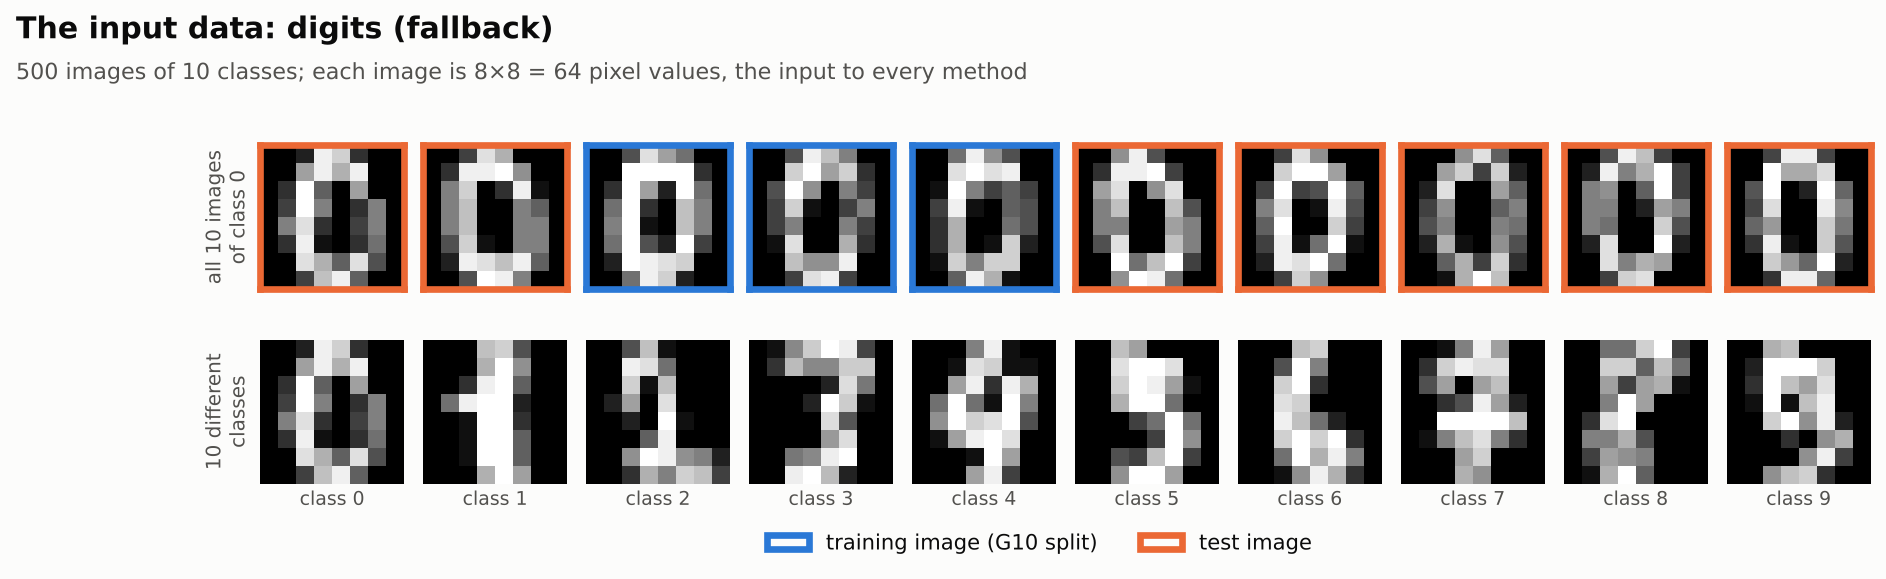

In [3]:
# Load the faces, draw the random splits, plot (folded)
def hist_eq(img):
    q = np.clip((img * 255).round().astype(int), 0, 255)
    cdf = np.cumsum(np.bincount(q.ravel(), minlength=256)).astype(float)
    return ((cdf - cdf.min()) / max(cdf.max() - cdf.min(), 1))[q]


try:
    from sklearn.datasets import fetch_olivetti_faces
    d = fetch_olivetti_faces(shuffle=False)
    images = np.stack([hist_eq(np.clip(zoom(im, (56 / 64, 46 / 64), order=1), 0, 1)) for im in d.images])
    labels, DATA, SETTINGS, SIDE, WHO = d.target, "ORL faces", (3, 4, 5), [4, 8, 16], "person"
except Exception:
    from sklearn.datasets import load_digits
    d = load_digits(); r = np.random.default_rng(SEED)
    keep = np.sort(np.concatenate([r.permutation(np.flatnonzero(d.target == c))[:50] for c in range(10)]))
    images, labels, DATA, SETTINGS, SIDE, WHO = d.images[keep] / 16, d.target[keep], "digits (fallback)", (5, 10, 20), [2, 4, 6, 8], "class"
    print("No internet: using scikit-learn digits instead of ORL.")
NC = len(np.unique(labels))
WHOS = "people" if WHO == "person" else "classes"
H_, W_ = images.shape[1:]
flat = lambda I: I.reshape(len(I), -1).T


def gm_splits(m, n_splits=5, seed=SEED):
    """Gm/Pn protocol: m random training images per class, the rest for testing."""
    r = np.random.default_rng(seed); out = []
    for _ in range(n_splits):
        tr = np.concatenate([r.permutation(np.flatnonzero(labels == c))[:m] for c in range(NC)])
        out.append((tr, np.setdiff1d(np.arange(len(labels)), tr)))
    return out


tr0 = set(gm_splits(SETTINGS[1], 1)[0][0])
fig, axes = plt.subplots(2, 10, figsize=(13, 3.9 if H_ > 20 else 3.3), gridspec_kw={"hspace": 0.35, "wspace": 0.12})
for ax, i in zip(axes[0], np.flatnonzero(labels == 0)[:10]):
    show_img(ax, images[i], TRAIN_C if i in tr0 else TEST_C)
for ax, c in zip(axes[1], np.unique(labels)[:10]):
    show_img(ax, images[np.flatnonzero(labels == c)[0]]); ax.set_xlabel(f"{WHO} {c}", fontsize=8.5, color=INK2, labelpad=3)
axes[0, 0].set_ylabel(f"all 10 images\nof {WHO} 0", fontsize=9, color=INK2)
axes[1, 0].set_ylabel(f"10 different\n{WHOS}", fontsize=9, color=INK2)
fig.legend(handles=[Patch(facecolor="none", edgecolor=TRAIN_C, lw=3, label=f"training image (G{SETTINGS[1]} split)"),
                    Patch(facecolor="none", edgecolor=TEST_C, lw=3, label="test image")],
           loc="lower center", bbox_to_anchor=(0.5, -0.06), ncol=2)
finish(fig, f"The input data: {DATA}",
       f"{len(labels)} images of {NC} {WHOS}; each image is {H_}×{W_} = {H_ * W_:,} pixel values, the input to every method")

Xs, t_s = make_s_curve(1500, noise=0.02, random_state=SEED); Xs = Xs.T; Xs[1] *= 3; Ns = Xs.shape[1]

# Part B: Existing algorithms in the framework (Sec. 2.2, Table 1)

None of these algorithms is new. The paper's point is that each one is the **same criterion with a particular graph $W$ and constraint $B$**:

| Algorithm | Graph $W$ | Constraint $B$ | Versions in the paper | Here |
|---|---|---|---|---|
| PCA | $W_{ij}=1/N$ (all pairs) | $I$ (keep the largest $\lambda$) | PCA (L), KPCA (K), 2DPCA (T) | all three |
| LDA | $W_{ij}=\delta_{c_ic_j}/n_{c_i}$ (same class) | $I-\tfrac1Nee^\top$ (PCA graph as penalty) | LDA (L), KDA (K), 2DLDA / DATER (T) | Fisherface, PCA+LDA, KDA, DATER |
| ISOMAP | $\tau(D_G) = -HSH/2$ (geodesic distances) | $I$ | direct (D) | S-curve |
| LLE | $M+M^\top-M^\top M$ (reconstruction weights) | $I$ | LLE (D), LEA (L) | S-curve, LEA |
| Laplacian Eigenmap | $e^{-\|x_i-x_j\|^2/t}$ on $k$NN pairs | $D$ | LE (D), LPP (L) | S-curve, LPP |

## B1. The graphs of Table 1

In [4]:
def W_pca(N):                                             # PCA: every pair, weight 1/N
    W = np.full((N, N), 1.0 / N); np.fill_diagonal(W, 0); return W


def B_centering(N):                                       # I - ee'/N  (= Laplacian of the PCA graph)
    return np.eye(N) - np.ones((N, N)) / N


def W_lda(y):                                             # LDA: same-class pairs, weight 1/n_c
    y = np.asarray(y); n = np.array([np.sum(y == c) for c in y], float)
    return (y[:, None] == y[None, :]) / n[:, None]


def isomap_tau(X, k):                                     # ISOMAP: tau(D_G) = -H S H / 2 (Appendix A)
    DG = shortest_path(kneighbors_graph(X.T, k, mode="distance"), directed=False)
    H = np.eye(len(DG)) - 1.0 / len(DG)
    return -H @ (DG ** 2) @ H / 2


def lle_weights(X, k, reg=1e-3):                          # LLE reconstruction weights, rows sum to 1
    Z = X.T; nb = np.argsort(cdist(Z, Z), 1)[:, 1:k + 1]; M = np.zeros((len(Z),) * 2)
    for i in range(len(Z)):
        G = Z[nb[i]] - Z[i]; C = G @ G.T + reg * np.trace(G @ G.T) * np.eye(k)
        w = np.linalg.solve(C, np.ones(k)); M[i, nb[i]] = w / w.sum()
    return M


def W_lle(X, k):                                          # LLE: M + M' - M'M (Appendix B)
    M = lle_weights(X, k); return M + M.T - M.T @ M


def W_heat_knn(X, k, t=None):                             # Laplacian Eigenmap / LPP: heat kernel on kNN pairs
    D2 = cdist(X.T, X.T, "sqeuclidean"); t = np.mean(D2) if t is None else t
    M = D2.copy(); np.fill_diagonal(M, np.inf)
    A = np.zeros_like(D2, bool); A[np.repeat(np.arange(len(D2)), k), np.argsort(M, 1)[:, :k].ravel()] = True
    A |= A.T
    return np.where(A, np.exp(-D2 / t), 0.0)

## B2. The direct embeddings: ISOMAP, LLE and Laplacian Eigenmap

These three manifold learners have no mapping for new points, so they are shown on the S-curve. Each one is the **same `direct_embedding` call**; only $(W, B)$ changes. The colour shows each point's position along the curve.

In [5]:
W_le = W_heat_knn(Xs, 10)
direct = {
    "ISOMAP: W = τ(D_G), B = I": direct_embedding(isomap_tau(Xs, 10), np.eye(Ns), 2, skip_trivial=False),
    "LLE: W = M+Mᵀ−MᵀM, B = I": direct_embedding(W_lle(Xs, 12), np.eye(Ns), 2),
    "Laplacian Eigenmap: B = D": direct_embedding(W_le, np.diag(W_le.sum(1)), 2),
}

Saved for slides: figures/02_existing_direct_embeddings_three_manifold_lea.png  (and .svg)


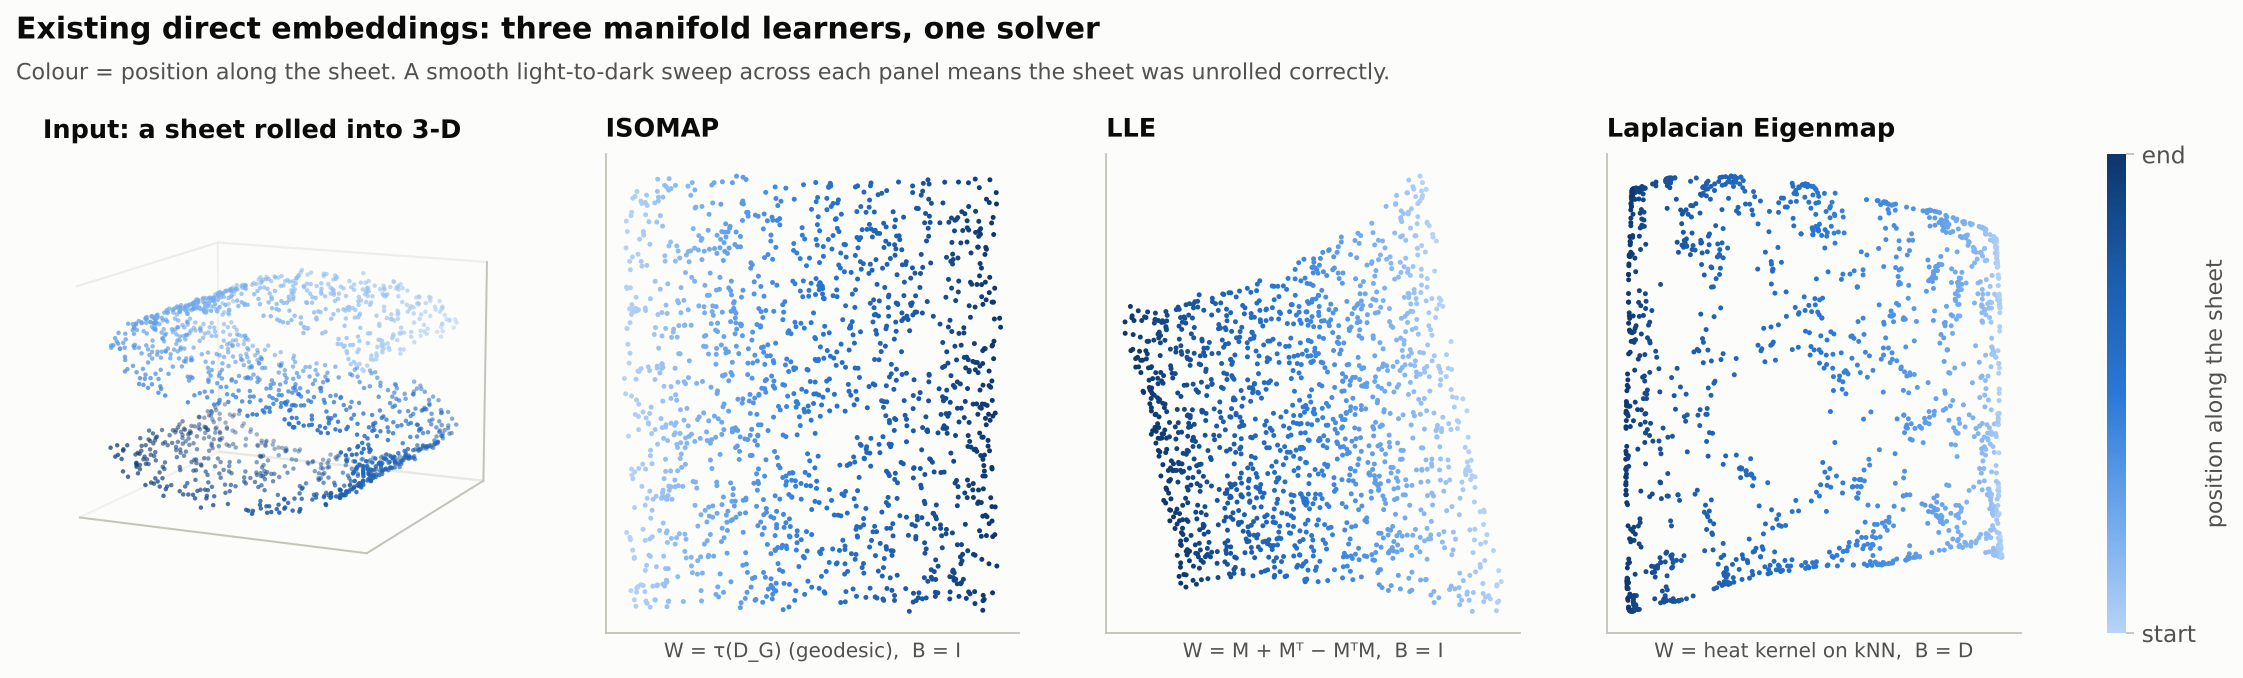

In [6]:
# Plot (folded)
fig = plt.figure(figsize=(14, 4.4))
gs = fig.add_gridspec(1, 5, width_ratios=[1.15, 1, 1, 1, 0.045], wspace=0.25, top=0.80, bottom=0.12, left=0.02, right=0.95)
ax = fig.add_subplot(gs[0], projection="3d")
ax.scatter(*Xs, c=t_s, cmap=SEQ, s=4, linewidths=0); ax.view_init(12, -65)
ax.set_xticks([]); ax.set_yticks([]); ax.set_zticks([]); ax.set_title("Input: a sheet rolled into 3-D", loc="left")
for pane in (ax.xaxis.pane, ax.yaxis.pane, ax.zaxis.pane):
    pane.set_facecolor(SURF); pane.set_edgecolor(GRID)
labels_wb = ["W = τ(D_G) (geodesic),  B = I", "W = M + Mᵀ − MᵀM,  B = I", "W = heat kernel on kNN,  B = D"]
for i, ((name, Y), wb) in enumerate(zip(direct.items(), labels_wb)):
    ax = fig.add_subplot(gs[i + 1]); sc = ax.scatter(Y[:, 0], Y[:, 1], c=t_s, cmap=SEQ, s=5, linewidths=0)
    ax.set_title(name.split(":")[0]); ax.set_xlabel(wb, fontsize=9); ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
cb = fig.colorbar(sc, cax=fig.add_subplot(gs[4]), ticks=[t_s.min(), t_s.max()])
cb.ax.set_yticklabels(["start", "end"]); cb.set_label("position along the sheet", color=INK2); cb.outline.set_visible(False)
fig.tight_layout = lambda *a, **k: None
finish(fig, "Existing direct embeddings: three manifold learners, one solver",
       "Colour = position along the sheet. A smooth light-to-dark sweep across each panel means the sheet was unrolled correctly.")

## B3. The linear, kernel and tensor versions used for classification

Each existing method below is a one-line call into Part A with its Table 1 graph. Linear methods work in a PCA subspace first, with $N-N_c$ dimensions (Fisherface, LPP, LEA) or a chosen energy (PCA+LDA), as in the paper's experiments.

In [7]:
# ---- Linear (L) ----
def pca(X, n=None):
    """PCA (Eq. 11): W = 1/N, B = I, keep the LARGEST eigenvalues. For m >> N this equals an SVD,
    which is what is computed here (the equivalence is checked in Part E)."""
    mu = X.mean(1, keepdims=True)
    U, s, _ = np.linalg.svd(X - mu, full_matrices=False)
    U = U[:, s > s[0] * 1e-10]
    return mu, U[:, :n] if n else U


def lda(Z, y, n_dims):                                    # LDA (Eq. 12): W_lda, penalty = PCA graph
    return unit(linear_embedding(Z, W_lda(y), B_centering(len(y)), n_dims))


def lpp(Z, k):                                            # LPP: linearised Laplacian Eigenmap, B = D
    W = W_heat_knn(Z, k)
    return unit(linear_embedding(Z, W, np.diag(W.sum(1)), len(Z)))


def lea(Z, k):                                            # LEA: linearised LLE, B = I  ->  w'XX'w = d
    return unit(linear_embedding(Z, W_lle(Z, k), np.eye(Z.shape[1]), len(Z)))


# ---- Kernel (K) ----
def lam(A, K):                                            # normalise kernel directions: ||w|| = 1 (Eq. 17)
    return A / np.sqrt(np.maximum(np.einsum("ip,ij,jp->p", A, K, A), 1e-12))[None]


def kpca(K):                                              # KPCA: PCA graph in feature space, largest lambda
    return lam(kernel_embedding(K, W_pca(len(K)), None, len(K), largest=True), K)


def kda(K, y):                                            # KDA: LDA graphs in feature space
    return lam(kernel_embedding(K, W_lda(y), B_centering(len(y)), len(y)), K)


# ---- Tensor (T) ----
def tpca(T, size):                                        # 2DPCA: PCA graph, U'U = I, largest lambda
    return tensor_embedding(T, W_pca(len(T)), None, size, largest=True)


def dater(T, y, size):                                    # DATER / 2DLDA: LDA graphs, tensorised
    return tensor_embedding(T, W_lda(y), W_pca(len(T)), size)

**What the existing linear methods do to the faces.** Three people are placed as 2-D points using each method's first two directions. Each person has their own colour **and** shape. Filled markers are training images and hollow markers are test images. The number under each panel is the 1-NN accuracy *in that 2-D view*, a quick measure of how well it separates the people.
* **PCA, LPP and LEA are unsupervised.** They never see the labels and follow the overall structure of the data, such as lighting and pose.
* **LDA is supervised.** It uses the labels to pull each person's images together.

Saved for slides: figures/03_existing_linear_methods_three_classes_in_two_.png  (and .svg)


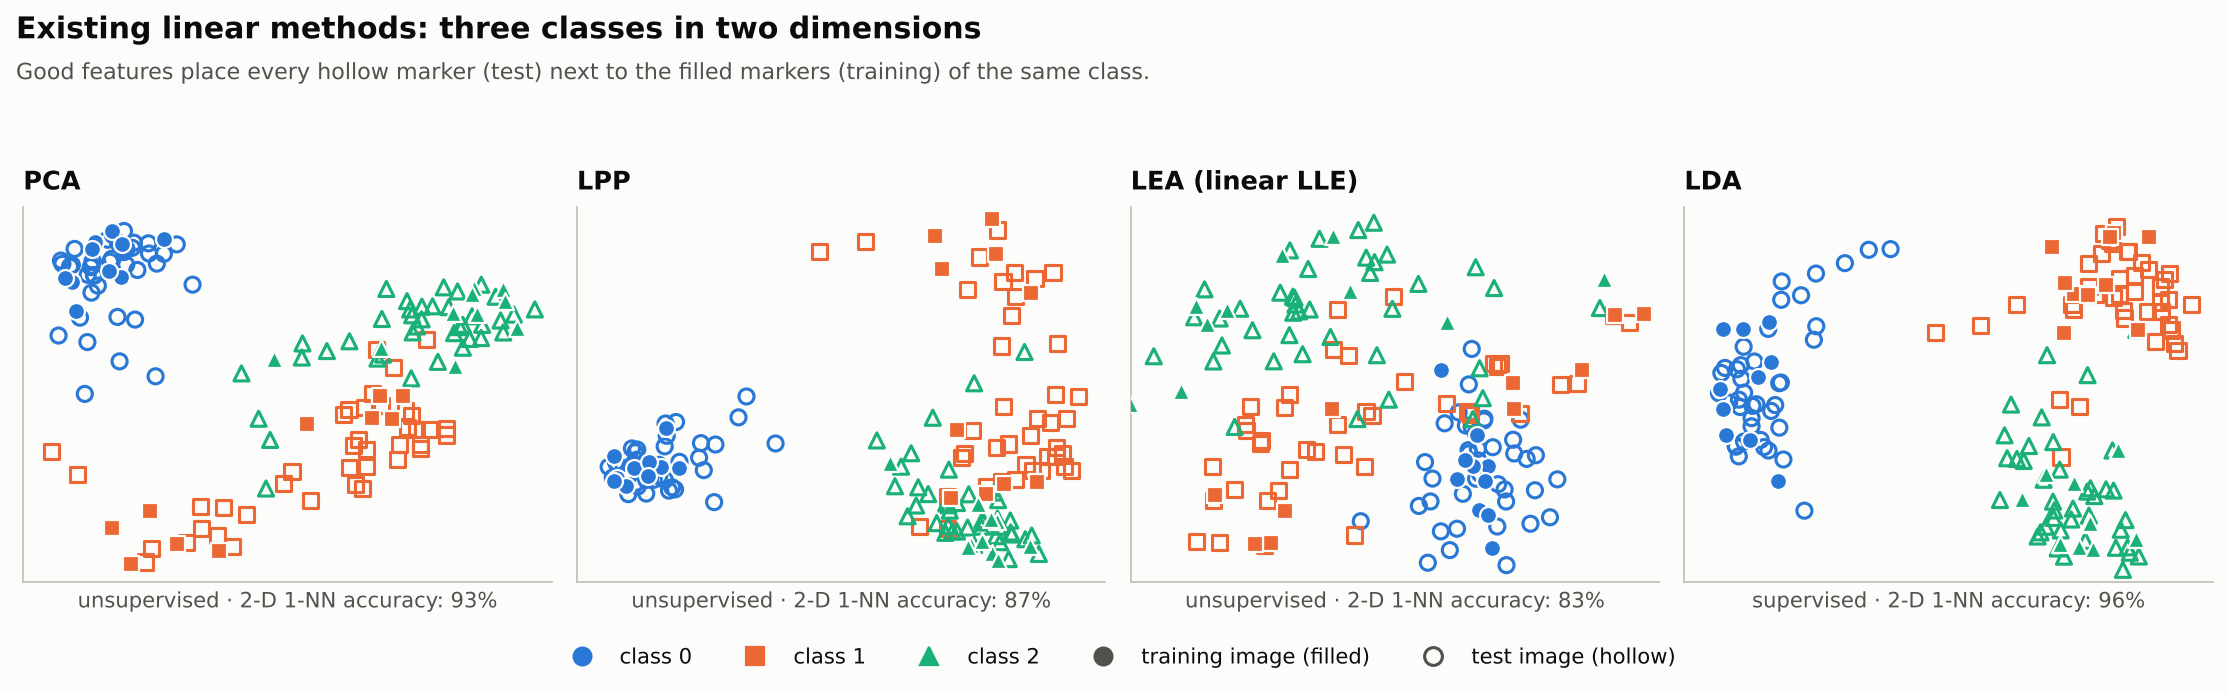

In [8]:
# Latent 2-D plots on 3 people (folded)
S = np.unique(labels)[:3]
tr_, te_ = gm_splits(SETTINGS[1], 1)[0]
trS = np.array([i for i in tr_ if labels[i] in S]); teS = np.array([i for i in te_ if labels[i] in S])
XS, XSt, yS, ySt = flat(images[trS]), flat(images[teS]), labels[trS], labels[teS]
muS, PS = pca(XS, min(len(trS) - len(S), 6)); ZS, ZSt = PS.T @ (XS - muS), PS.T @ (XSt - muS)


def latent_panel(ax, Wv, title, tag=""):
    Y, Yt = Wv.T @ ZS, Wv.T @ ZSt
    for k, c in enumerate(S):
        ax.scatter(*Yt[:, ySt == c], s=46, marker=CLASS_M[k], facecolors="none", edgecolors=CLASS_C[k], linewidths=1.4, zorder=2)
        ax.scatter(*Y[:, yS == c], s=58, marker=CLASS_M[k], color=CLASS_C[k], edgecolors=SURF, linewidths=1.0, zorder=3)
    lo, hi = np.percentile(np.c_[Y, Yt], [1, 99], axis=1); pad = 0.08 * (hi - lo)
    ax.set_xlim(lo[0] - pad[0], hi[0] + pad[0]); ax.set_ylim(lo[1] - pad[1], hi[1] + pad[1])
    ax.set_xticks([]); ax.set_yticks([])
    ax.set_title(title); ax.set_xlabel(f"{tag}2-D 1-NN accuracy: {nn_acc(Y, Yt, yS, ySt):.0%}", fontsize=9.5, color=INK2)


def latent_legend(fig, y=-0.08):
    h = [Line2D([], [], marker=CLASS_M[k], ls="", ms=8, color=CLASS_C[k], label=f"{WHO} {S[k]}") for k in range(len(S))]
    h += [Line2D([], [], marker="o", ls="", ms=8, color=INK2, label="training image (filled)"),
          Line2D([], [], marker="o", ls="", ms=8, markerfacecolor="none", markeredgecolor=INK2, markeredgewidth=1.4, label="test image (hollow)")]
    fig.legend(handles=h, loc="lower center", bbox_to_anchor=(0.5, y), ncol=len(h))


fig, axes = plt.subplots(1, 4, figsize=(14, 3.9))
for ax, (title, tag, Wv) in zip(axes, [("PCA", "unsupervised · ", np.eye(len(ZS))[:, :2]), ("LPP", "unsupervised · ", lpp(ZS, 5)[:, :2]),
                                       ("LEA (linear LLE)", "unsupervised · ", lea(ZS, 5)[:, :2]), ("LDA", "supervised · ", lda(ZS, yS, 2))]):
    latent_panel(ax, Wv, title, tag)
latent_legend(fig)
finish(fig, f"Existing linear methods: three {WHOS} in two dimensions",
       f"Good features place every hollow marker (test) next to the filled markers (training) of the same {WHO}.")

# Part C: What the paper proposes, Marginal Fisher Analysis (Sec. 3)

**The motivation: LDA's two limitations.**
* It describes each class only by its mean and scatter, which implicitly assumes a single Gaussian blob per class.
* It yields at most $N_c-1$ directions, because $S_B$ has rank at most $N_c-1$.

**The design: two new graphs that watch the class border, not the class centre.**
* **Intrinsic graph, intraclass compactness (Eq. 13):** $W_{ij}=1$ if $i$ is among the $k_1$ nearest **same-class** neighbours of $j$, or $j$ of $i$.
* **Penalty graph, interclass separability (Eq. 14):** $W^p_{ij}=1$ if $(i,j)$ is among the $k_2$ **closest pairs crossing the class border**, for the class of $i$ or of $j$.

$$w^* = \arg\min_w \frac{w^\top X(D-W)X^\top w}{w^\top X(D^p-W^p)X^\top w}\qquad\text{(Marginal Fisher Criterion, Eq. 15)}$$

It comes in three versions, one per extension:

| Version | How | Paper |
|---|---|---|
| **MFA** | PCA → graphs → Eq. 15 → $w=W_{PCA}w^*$ | Sec. 3.1 |
| **Kernel MFA** | same graphs, neighbours measured by kernel distance $\sqrt{k_{ii}+k_{jj}-2k_{ij}}$; new points by $F(x)=\lambda\sum_i\alpha_ik(x,x_i)$ | Sec. 3.2, Eqs. 16–17 |
| **Tensor MFA** | same graphs, image kept as a matrix, alternating optimisation | Sec. 3.3, Eq. 18 |

In [9]:
def mfa_graphs(y, k1, k2, dist):
    """Eq. 13 (intrinsic) and Eq. 14 (penalty) from a pairwise distance matrix."""
    y = np.asarray(y); W = np.zeros((len(y),) * 2); Wp = np.zeros_like(W)
    for c in np.unique(y):
        idx, out = np.flatnonzero(y == c), np.flatnonzero(y != c)
        sub = dist[np.ix_(idx, idx)].copy(); np.fill_diagonal(sub, np.inf)       # k1 same-class neighbours
        k = min(k1, len(idx) - 1)
        r, s = np.repeat(idx, k), idx[np.argsort(sub, 1)[:, :k].ravel()]
        W[r, s] = W[s, r] = 1
        sub = dist[np.ix_(idx, out)]; k = min(k2, sub.size)                    # k2 closest cross-class pairs
        r, s = np.unravel_index(np.argpartition(sub, k - 1, axis=None)[:k], sub.shape)
        Wp[idx[r], out[s]] = Wp[out[s], idx[r]] = 1
    return W, Wp


def mfa(Z, y, k1, k2, n_dims=None):                      # MFA (Eq. 15): linearisation with B = L^p
    W, Wp = mfa_graphs(y, k1, k2, cdist(Z.T, Z.T))
    return unit(linear_embedding(Z, W, laplacian(Wp), n_dims or len(Z)))


def kmfa(K, y, k1, k2):                                  # Kernel MFA (Eqs. 16-17)
    dK = np.diag(K)
    W, Wp = mfa_graphs(y, k1, k2, np.sqrt(np.maximum(dK[:, None] + dK[None, :] - 2 * K, 0)))
    return lam(kernel_embedding(K, W, laplacian(Wp), len(K)), K)


def tmfa(T, y, k1, k2, size):                            # Tensor MFA (Eq. 18)
    W, Wp = mfa_graphs(y, k1, k2, cdist(flat(T).T, flat(T).T))
    return tensor_embedding(T, W, Wp, size)

## C1. Why the new graphs matter: the non-Gaussian case (Sec. 4.2, Fig. 6)

Two classes sit in thin bands just above and below the boundary, and each has a far-away cluster. The far clusters drag the class **means** diagonally, so LDA tilts and the bands overlap. MFA only sees the border pairs and picks the vertical direction ($k_1=5$, $k_2=250$, as in the paper).

Saved for slides: figures/04_why_the_proposal_lda_fails_when_classes_are_n.png  (and .svg)


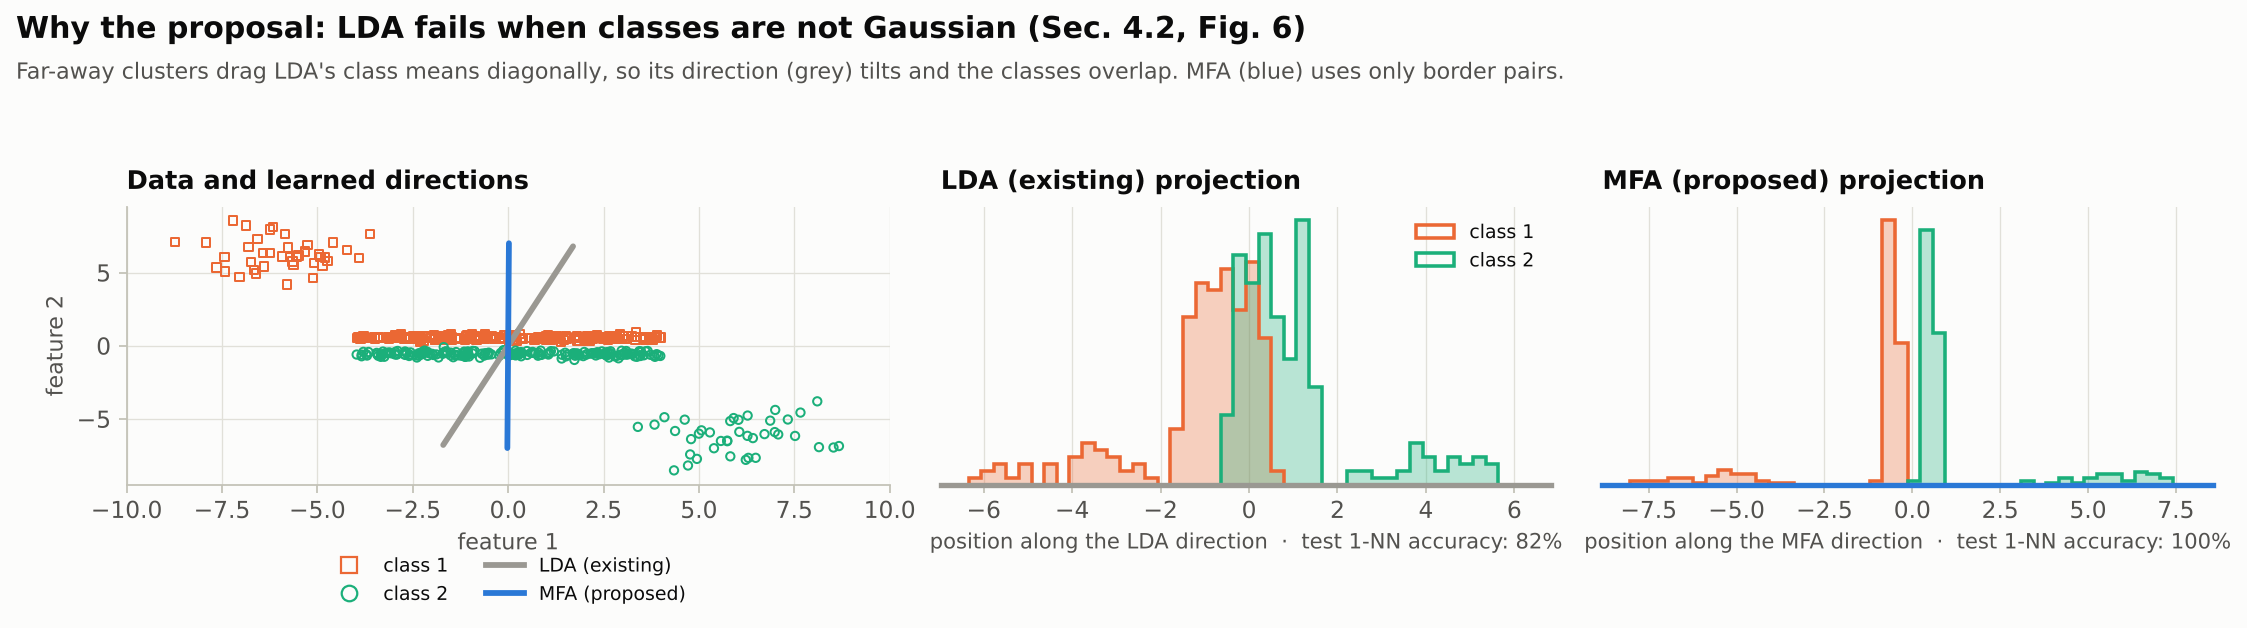

In [10]:
# Toy data, fit and plot (folded)
def toy(seed, nb=200, nc=40):
    r = np.random.default_rng(seed)
    A = np.r_[np.c_[r.uniform(-4, 4, nb), r.normal(.55, .12, nb)], np.c_[r.normal(-6, 1.2, nc), r.normal(6, 1.2, nc)]]
    B = np.r_[np.c_[r.uniform(-4, 4, nb), r.normal(-.55, .12, nb)], np.c_[r.normal(6, 1.2, nc), r.normal(-6, 1.2, nc)]]
    return np.r_[A, B].T, np.r_[np.zeros(nb + nc, int), np.ones(nb + nc, int)]


Xt, yt = toy(1); Xv, yv = toy(2)
TOY_C, TOY_M = ["#eb6834", "#1baf7a"], ["s", "o"]
dirs = {"LDA (existing)": (lda(Xt, yt, 1)[:, 0], EXISTING), "MFA (proposed)": (mfa(Xt, yt, 5, 250, 1)[:, 0], PROPOSED)}
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2), gridspec_kw={"width_ratios": [1.25, 1, 1]})
ax = axes[0]
for k in (0, 1):
    ax.scatter(*Xt[:, yt == k], marker=TOY_M[k], s=14, facecolors="none", edgecolors=TOY_C[k], linewidths=0.9)
for name, (w, col) in dirs.items():
    u = w * np.sign(w[1]); ax.plot([-7 * u[0], 7 * u[0]], [-7 * u[1], 7 * u[1]], color=col, lw=2.6, solid_capstyle="round")
ax.set_xlim(-10, 10); ax.set_ylim(-9.5, 9.5); ax.set_title("Data and learned directions")
ax.set_xlabel("feature 1"); ax.set_ylabel("feature 2")
ax.legend(handles=[Line2D([], [], marker=TOY_M[k], ls="", ms=7, markerfacecolor="none", markeredgecolor=TOY_C[k], label=f"class {k + 1}") for k in (0, 1)]
          + [Line2D([], [], color=c, lw=2.6, label=n) for n, (w, c) in dirs.items()],
          loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=2, fontsize=8.5)
for ax, (name, (w, col)) in zip(axes[1:], dirs.items()):
    p, q = w @ Xt, w @ Xv
    bins = np.linspace(np.percentile(p, 0.5), np.percentile(p, 99.5), 45)
    for k in (0, 1):
        ax.hist(q[yv == k], bins, color=TOY_C[k], alpha=0.30, histtype="stepfilled")
        ax.hist(q[yv == k], bins, color=TOY_C[k], lw=1.6, histtype="step", label=f"class {k + 1}")
    acc = nn_acc(p[None], q[None], yt, yv)
    ax.set_title(f"{name} projection"); ax.set_yticks([]); ax.grid(axis="y", visible=False)
    ax.set_xlabel(f"position along the {name.split()[0]} direction  ·  test 1-NN accuracy: {acc:.0%}", fontsize=9.5)
    for sp in ("left",):
        ax.spines[sp].set_visible(False)
    ax.spines["bottom"].set_color(col); ax.spines["bottom"].set_linewidth(2.4)
axes[1].legend(loc="upper right", fontsize=8.5)
finish(fig, "Why the proposal: LDA fails when classes are not Gaussian (Sec. 4.2, Fig. 6)",
       "Far-away clusters drag LDA's class means diagonally, so its direction (grey) tilts and the classes overlap. MFA (blue) uses only border pairs.")

## C2. MFA on the faces: input → intermediate → output

Each row follows one *test* image through MFA's four steps (Sec. 3.1):
1. **Input:** the raw image.
2. **Intermediate, step 1 (PCA):** what the PCA subspace keeps of it, mapped back to pixels.
3. **Output, steps 2–4:** the MFA feature vector. The first 20 values are shown.
4. **Result:** the nearest training image in MFA space. A green frame with ✓ means the right person was matched; a red frame with ✗ means a wrong one.

Saved for slides: figures/05_proposed_mfa_step_by_step_on_test_images.png  (and .svg)


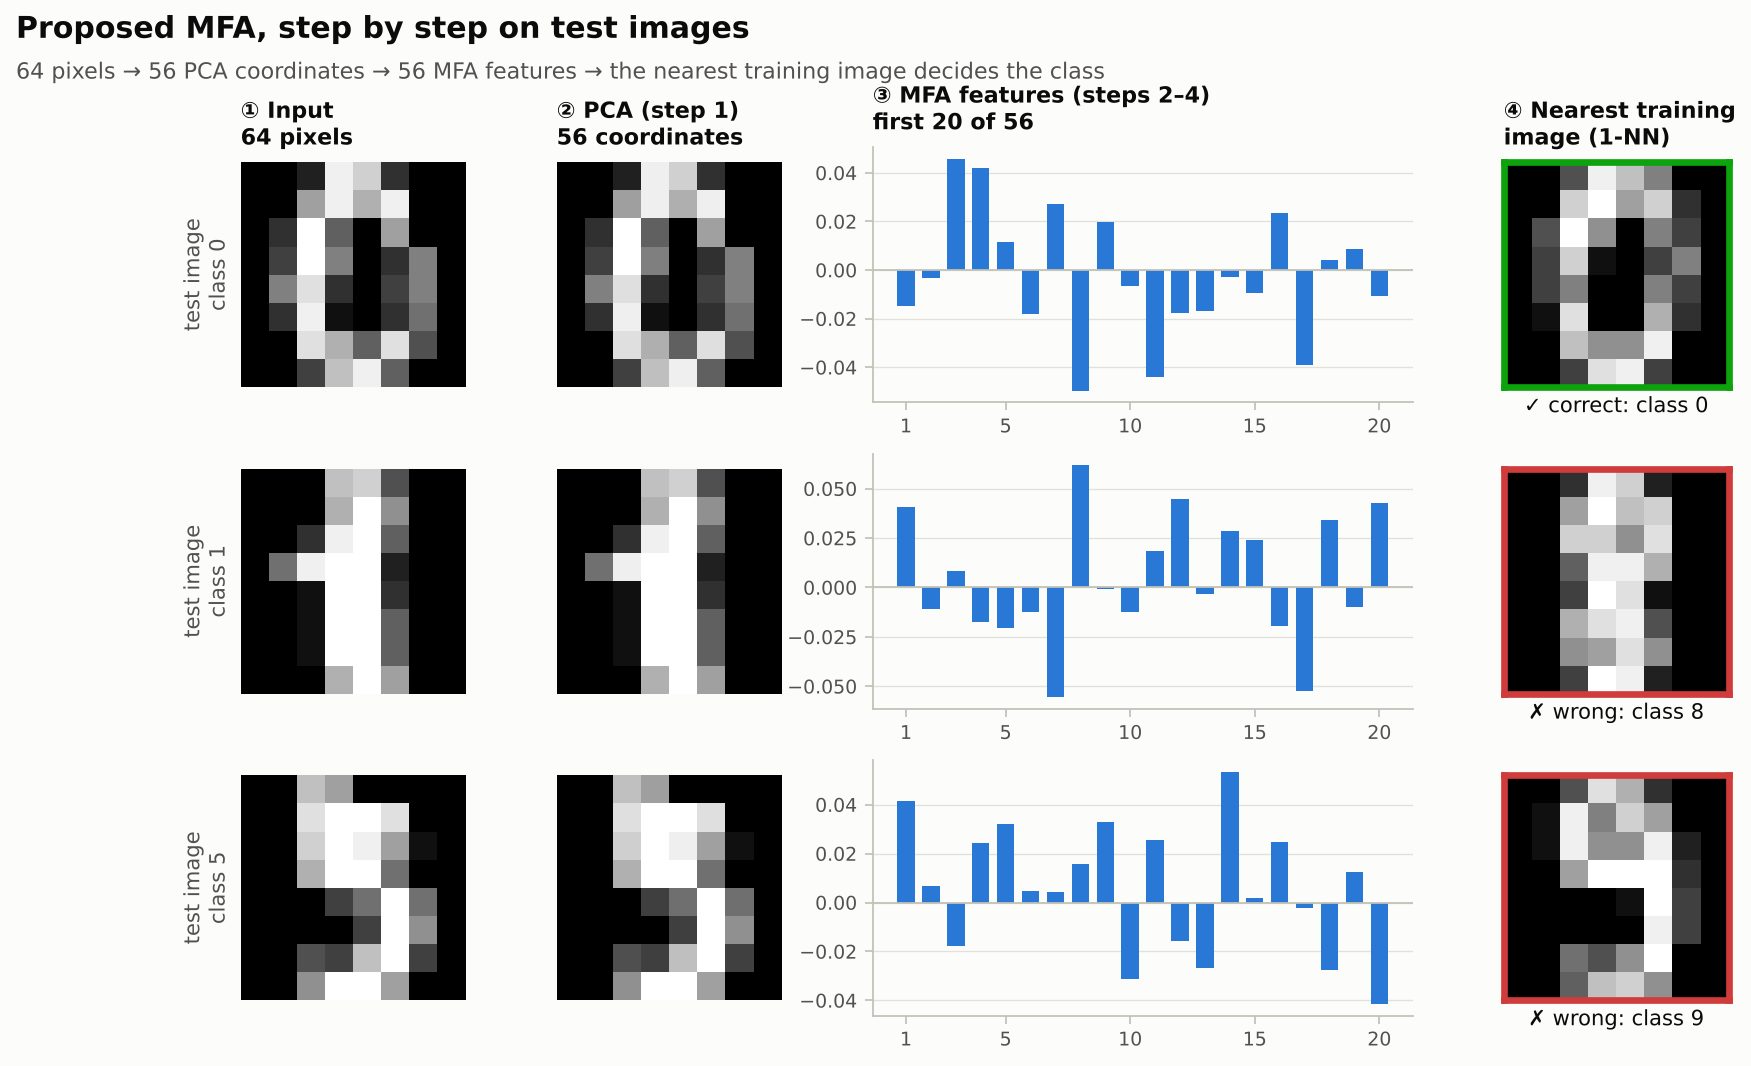

In [11]:
# MFA pipeline on single test images (folded); graphs use k1 = 2, k2 = 40
tr, te = gm_splits(SETTINGS[1], 1)[0]
Xtr, Xte, ytr, yte = flat(images[tr]), flat(images[te]), labels[tr], labels[te]
mu, P = pca(Xtr, len(tr) - NC); Z, Zt = P.T @ (Xtr - mu), P.T @ (Xte - mu)
w = mfa(Z, ytr, min(2, SETTINGS[1] - 1), 40); F, Ft = w.T @ Z, w.T @ Zt
nn_all = np.argmin(sqdist(F, Ft), axis=0)
wrong = [t for t in range(len(yte)) if ytr[nn_all[t]] != yte[t]]
picks = [np.flatnonzero(yte == c)[0] for c in range(2)]
picks.append(next((t for t in wrong if t not in picks), np.flatnonzero(yte == 2)[0]))   # show one mistake if there is one
fig, axes = plt.subplots(len(picks), 4, figsize=(12, 2.35 * len(picks)), gridspec_kw={"width_ratios": [1, 1, 2.4, 1], "wspace": 0.3})
heads = [f"① Input\n{H_ * W_:,} pixels", f"② PCA (step 1)\n{P.shape[1]} coordinates",
         f"③ MFA features (steps 2–4)\nfirst 20 of {F.shape[0]}", "④ Nearest training\nimage (1-NN)"]
for row, t in zip(axes, picks):
    nn = nn_all[t]; ok = ytr[nn] == yte[t]
    show_img(row[0], Xte[:, t].reshape(H_, W_))
    show_img(row[1], (mu[:, 0] + P @ Zt[:, t]).reshape(H_, W_))
    row[2].bar(range(1, 21), Ft[:20, t], color=PROPOSED, width=0.7); row[2].axhline(0, color=AXIS, lw=0.8)
    row[2].set_xticks([1, 5, 10, 15, 20]); row[2].grid(axis="x", visible=False); row[2].tick_params(labelsize=8.5)
    show_img(row[3], Xtr[:, nn].reshape(H_, W_), GOOD if ok else BAD)
    row[3].set_xlabel(("✓ correct: " if ok else "✗ wrong: ") + f"{WHO} {ytr[nn]}", fontsize=9.5, color=INK)
    row[0].set_ylabel(f"test image\n{WHO} {yte[t]}", fontsize=9.5, color=INK2)
for ax, h in zip(axes[0], heads):
    ax.set_title(h, fontsize=10)
finish(fig, "Proposed MFA, step by step on test images",
       f"{H_ * W_:,} pixels → {P.shape[1]} PCA coordinates → {F.shape[0]} MFA features → the nearest training image decides the {WHO}")

## C3. Existing LDA vs proposed MFA in two dimensions

These are the same three people as in Part B, embedded by LDA (existing) and by MFA (proposed). Both use the labels: LDA through class means, MFA through $k_1$-neighbour and border-pair graphs.

Saved for slides: figures/06_existing_lda_vs_proposed_mfa_three_classes_in.png  (and .svg)


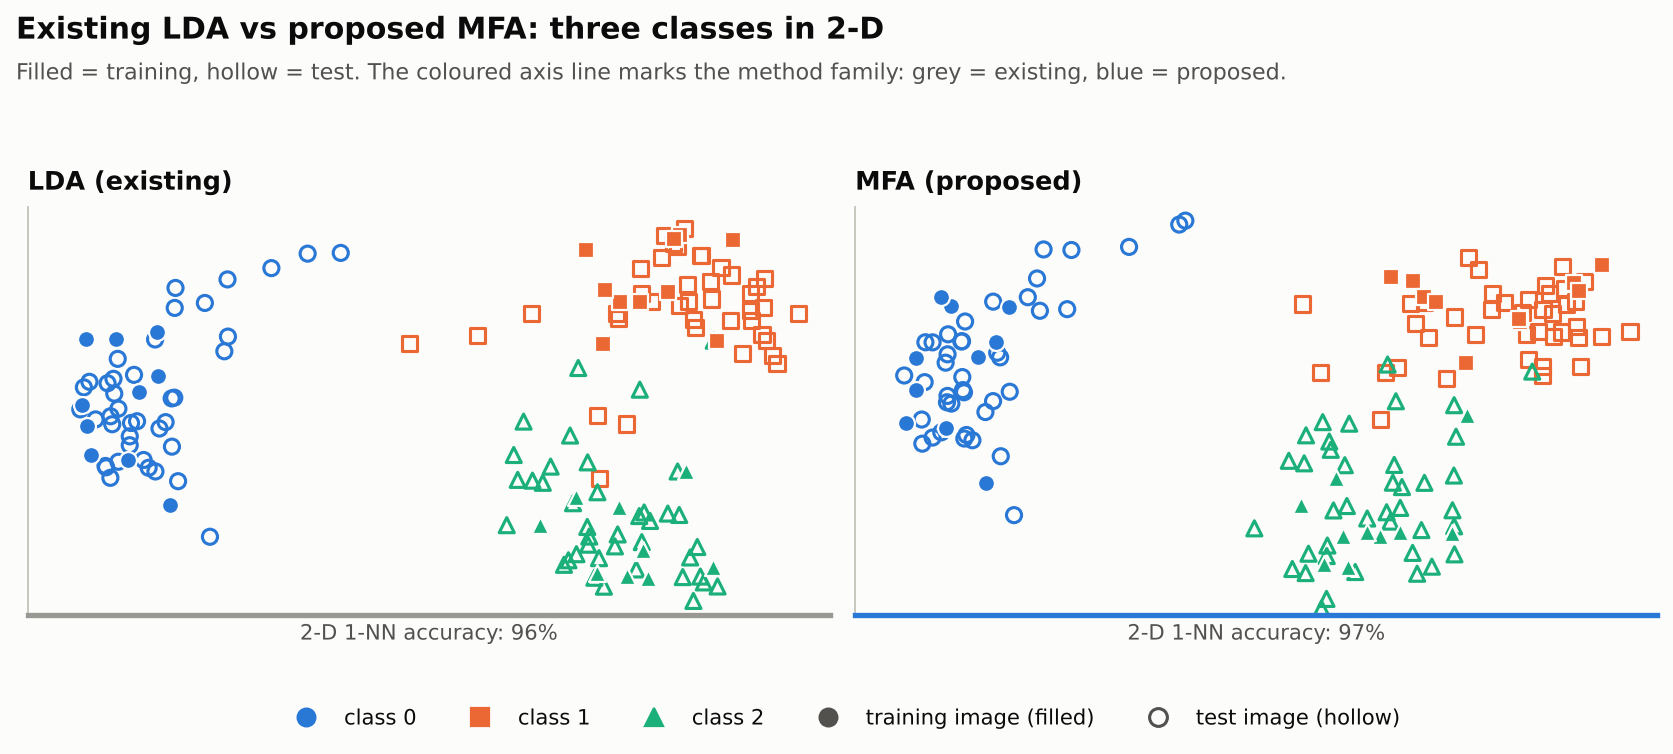

In [12]:
# Plot (folded)
fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.1))
latent_panel(axes[0], lda(ZS, yS, 2), "LDA (existing)", "")
latent_panel(axes[1], mfa(ZS, yS, min(2, SETTINGS[1] - 1), 20, 2), "MFA (proposed)", "")
for ax, col in zip(axes, (EXISTING, PROPOSED)):
    ax.spines["bottom"].set_color(col); ax.spines["bottom"].set_linewidth(2.4)
latent_legend(fig, y=-0.12)
finish(fig, f"Existing LDA vs proposed MFA: three {WHOS} in 2-D",
       f"Filled = training, hollow = test. The coloured axis line marks the method family: grey = existing, blue = proposed.")

# Part D: All methods on face recognition (Sec. 4.1 protocol)

**Protocol.** *Gm/Pn*: $m$ random training images per person and the rest for testing. Five random splits per setting, and a 1-nearest-neighbour classifier on the reduced features. As in the paper, each method reports its best mean accuracy over a small hyper-parameter grid and over output dimensions. That choice is made on the test data, so all numbers are optimistic, but every method gets the same treatment.

**Methods compared:**

| | Linear (L) | Kernel (K) | Tensor (T) |
|---|---|---|---|
| **Existing (Table 1)** | PCA · Fisherface (PCA→LDA) · PCA+LDA · LPP · LEA | KPCA · KDA | 2DPCA · DATER |
| **Proposed (Sec. 3)** | MFA · PCA+MFA | KMFA | TMFA |

**Grids:**
* $k_1$: up to 5 values in $[2, m-1]$. $k_2$: 20, 40, 80, 160.
* PCA energy: 90 %, 95 %, 98 %.
* Gaussian kernel: $\delta = 2^{(n-10)/2.5}\delta_0$ for $n = 8, 10, 12$.
* LPP and LEA neighbours: $k = 3, 5, 10$.
* Tensor output sizes from a small grid. TMFA's $(k_1, k_2)$ is chosen at one size first.

The run takes a few minutes on a laptop.

In [13]:
# The experiment loop (folded)
K2S, ENERGIES, KERNEL_NS, KNN = [20, 40, 80, 160], [0.90, 0.95, 0.98], [8, 10, 12], [3, 5, 10]
SIZES = [(a, b) for a in SIDE for b in SIDE]


def k1_grid(m):
    return sorted({int(round(v)) for v in np.linspace(2, max(m - 1, 2), 5)} & set(range(1, m))) or [1]


def prefix_acc(Ztr, Zte, ytr, yte):
    """1-NN accuracy using the first d features, for every d."""
    dist = np.zeros((Zte.shape[1], Ztr.shape[1])); out = []
    for f in range(len(Ztr)):
        dist += (Zte[f][:, None] - Ztr[f][None, :]) ** 2
        out.append(np.mean(ytr[np.argmin(dist, 1)] == yte))
    return np.array(out)


def run_split(tr, te, m):
    Xtr, Xte, ytr, yte = flat(images[tr]), flat(images[te]), labels[tr], labels[te]
    K1S, res = k1_grid(m), {}
    proj = lambda w, A, B: prefix_acc(w.T @ A, w.T @ B, ytr, yte)
    # Linear: PCA, and the PCA subspaces the other linear methods work in
    mu, P = pca(Xtr); res["PCA"] = {(): prefix_acc(P.T @ (Xtr - mu), P.T @ (Xte - mu), ytr, yte)}
    mu, P = pca(Xtr, len(tr) - NC); Z, Zt = P.T @ (Xtr - mu), P.T @ (Xte - mu)
    res["Fisherface"] = {(): proj(lda(Z, ytr, NC - 1), Z, Zt)}
    res["LPP"] = {(k,): proj(lpp(Z, k), Z, Zt) for k in KNN}
    res["LEA"] = {(k,): proj(lea(Z, k), Z, Zt) for k in KNN}
    res["MFA"] = {(k1, k2): proj(mfa(Z, ytr, k1, k2), Z, Zt) for k1 in K1S for k2 in K2S}
    res["PCA+LDA"], res["PCA+MFA"] = {}, {}
    full_mu, full_P = pca(Xtr)
    s2 = np.linalg.norm(full_P.T @ (Xtr - full_mu), axis=1) ** 2
    for e in ENERGIES:
        n_e = int(np.searchsorted(np.cumsum(s2) / s2.sum(), e) + 1)
        Ze, Zet = full_P[:, :n_e].T @ (Xtr - full_mu), full_P[:, :n_e].T @ (Xte - full_mu)
        res["PCA+LDA"][(e,)] = proj(lda(Ze, ytr, min(NC - 1, n_e)), Ze, Zet)
        for k1 in K1S:
            for k2 in K2S:
                res["PCA+MFA"][(e, k1, k2)] = proj(mfa(Ze, ytr, k1, k2), Ze, Zet)
    # Kernel: Gaussian kernel, delta = 2^((n-10)/2.5) delta0
    D2, D2t = sqdist(Xtr, Xtr), sqdist(Xtr, Xte)
    delta0 = np.sqrt(np.mean(np.sum((Xtr - Xtr.mean(1, keepdims=True)) ** 2, 0)))
    res["KPCA"], res["KDA"], res["KMFA"] = {}, {}, {}
    for n in KERNEL_NS:
        dl = 2 ** ((n - 10) / 2.5) * delta0
        K, Kt = np.exp(-D2 / dl ** 2), np.exp(-D2t / dl ** 2)
        res["KPCA"][(n,)] = proj(kpca(K), K, Kt)
        res["KDA"][(n,)] = proj(kda(K, ytr), K, Kt)
        for k1 in K1S:
            for k2 in K2S:
                res["KMFA"][(n, k1, k2)] = proj(kmfa(K, ytr, k1, k2), K, Kt)
    # Tensor: images kept as matrices
    T, Tt = images[tr], images[te]
    t_acc = lambda U: np.array([nn_acc(tensor_features(T, *U), tensor_features(Tt, *U), ytr, yte)])
    res["2DPCA"] = {(s,): t_acc(tpca(T, s)) for s in SIZES}
    res["DATER"] = {(s,): t_acc(dater(T, ytr, s)) for s in SIZES}
    mid = (SIDE[1], SIDE[1])
    k1b, k2b = max(((a, b) for a in K1S for b in K2S), key=lambda g: t_acc(tmfa(T, ytr, *g, mid))[0])
    res["TMFA"] = {(s,): t_acc(tmfa(T, ytr, k1b, k2b, s)) for s in SIZES}       # (k1, k2) re-chosen per split
    return res


EXISTING_M = ["PCA", "Fisherface", "PCA+LDA", "LPP", "LEA", "KPCA", "KDA", "2DPCA", "DATER"]
PROPOSED_M = ["MFA", "PCA+MFA", "KMFA", "TMFA"]
TYPE = {"PCA": "L", "Fisherface": "L", "PCA+LDA": "L", "LPP": "L", "LEA": "L", "KPCA": "K", "KDA": "K",
        "2DPCA": "T", "DATER": "T", "MFA": "L", "PCA+MFA": "L", "KMFA": "K", "TMFA": "T"}
results, t0 = {}, time.time()
for m in SETTINGS:
    splits = gm_splits(m)
    runs = [run_split(tr, te, m) for tr, te in splits]
    setting = f"G{m}/P{len(splits[0][1]) // NC}"
    results[setting] = {}
    for name in EXISTING_M + PROPOSED_M:          # best mean accuracy over configurations and output dimensions
        common = {c: min(len(r_[name][c]) for r_ in runs) for c in runs[0][name]}
        curves = {c: np.mean([r_[name][c][:common[c]] for r_ in runs], 0) for c in runs[0][name]}
        cfg, curve = max(curves.items(), key=lambda kv: kv[1].max())
        d_best = int(np.argmax(curve)); per = [r_[name][cfg][d_best] for r_ in runs]
        size = next((c for c in cfg if isinstance(c, tuple)), None)
        results[setting][name] = dict(acc=100 * np.mean(per), std=100 * np.std(per),
                                      dim=f"{size[0]}×{size[1]}" if size else str(d_best + 1))
    print(f"{setting}: done ({time.time() - t0:.0f}s)")

G5/P45: done (3s)
G10/P40: done (13s)
G20/P30: done (37s)


## D1. The combined accuracy table

Each cell shows mean 1-NN accuracy (%) ± standard deviation over 5 splits, with the chosen output dimension in brackets. Rows shaded blue are the paper's proposed MFA family. The **bold** cell in each column is the best method for that setting.

In [14]:
# Tables (folded)
ALL = EXISTING_M + PROPOSED_M
acc = pd.DataFrame({s: {n: res[n]["acc"] for n in ALL} for s, res in results.items()})
cells_ = pd.DataFrame({s: {n: f"{res[n]['acc']:.1f} ± {res[n]['std']:.1f}  [{res[n]['dim']}]" for n in ALL} for s, res in results.items()})
cells_.insert(0, "type", [TYPE[n] for n in ALL])
cells_.insert(0, "group", ["Existing (Table 1)"] * len(EXISTING_M) + ["Proposed (Sec. 3)"] * len(PROPOSED_M))
cells_.index.name = "method"
best = {s: acc[s].idxmax() for s in acc.columns}
TH = [{"selector": "th", "props": [("text-align", "left"), ("font-weight", "600"), ("color", INK), ("border-bottom", f"1px solid {AXIS}"), ("padding", "6px 10px")]},
      {"selector": "td", "props": [("padding", "5px 10px"), ("font-variant-numeric", "tabular-nums"), ("color", INK)]},
      {"selector": "caption", "props": [("caption-side", "top"), ("text-align", "left"), ("font-weight", "600"), ("color", INK), ("padding-bottom", "6px")]}]


def style_rows(row):
    bg = f"background-color: {PROPOSED_BG}" if row["group"].startswith("Proposed") else ""
    return [bg + ("; font-weight: 700" if c in best and best[c] == row.name else "") for c in row.index]


display(cells_.style.apply(style_rows, axis=1).set_table_styles(TH)
        .set_caption(f"{DATA}: 1-NN recognition accuracy (%), mean ± std over 5 random splits  [chosen output dimension]"))

PAIRS = [("Linear", "Fisherface", "MFA"), ("Linear, tuned PCA", "PCA+LDA", "PCA+MFA"), ("Kernel", "KDA", "KMFA"), ("Tensor", "DATER", "TMFA")]
delta = pd.DataFrame({s: {f"{a} → {b}": acc.loc[b, s] - acc.loc[a, s] for _, a, b in PAIRS} for s in acc.columns})
delta.index.name = "existing → proposed"
fmt = lambda v: ("▲ +" if v > 0.05 else ("▼ −" if v < -0.05 else "= ")) + f"{abs(v):.1f}"
colr = lambda v: f"color: {GOOD_TXT}; font-weight: 600" if v > 0.05 else (f"color: {BAD}; font-weight: 600" if v < -0.05 else f"color: {INK2}")
display(delta.style.format(fmt).map(colr).set_table_styles(TH)
        .set_caption("Gain of each proposed method over its LDA-based counterpart (accuracy points; ▲ = MFA better)"))

,group,type,G5/P45,G10/P40,G20/P30
method,,,,,
PCA,Existing (Table 1),L,83.6 ± 2.5 [42],90.2 ± 0.6 [46],94.1 ± 0.9 [44]
Fisherface,Existing (Table 1),L,70.8 ± 3.5 [9],75.6 ± 1.9 [9],87.1 ± 0.2 [9]
PCA+LDA,Existing (Table 1),L,80.5 ± 2.0 [9],88.2 ± 0.9 [9],91.9 ± 1.0 [9]
LPP,Existing (Table 1),L,76.3 ± 4.2 [34],80.8 ± 2.5 [40],91.2 ± 0.9 [48]
LEA,Existing (Table 1),L,77.5 ± 2.0 [40],82.6 ± 1.4 [45],91.3 ± 2.1 [54]
KPCA,Existing (Table 1),K,83.6 ± 2.7 [49],90.0 ± 0.6 [99],93.7 ± 1.1 [143]
KDA,Existing (Table 1),K,82.0 ± 3.7 [45],91.1 ± 1.2 [74],95.1 ± 1.1 [56]
2DPCA,Existing (Table 1),T,84.0 ± 2.9 [6×8],90.2 ± 0.9 [8×4],93.9 ± 0.7 [8×4]
DATER,Existing (Table 1),T,77.6 ± 3.8 [8×4],84.7 ± 1.7 [6×4],85.9 ± 4.5 [6×8]


,G5/P45,G10/P40,G20/P30
existing → proposed,,,
Fisherface → MFA,▲ +4.5,▲ +3.2,▲ +3.7
PCA+LDA → PCA+MFA,▲ +2.1,▲ +2.5,▲ +2.7
KDA → KMFA,▲ +1.7,▼ −0.1,▲ +0.3
DATER → TMFA,▼ −0.3,▲ +1.2,▲ +3.9


## D2. The paper's central comparison: MFA against its LDA-based counterpart

Each line joins an existing LDA-based method (grey) to its proposed MFA version (blue), on the same splits. A blue dot to the right of the grey one means MFA wins, and the number is the gain in accuracy points.

Saved for slides: figures/07_does_mfa_beat_lda_each_proposed_method_vs_its.png  (and .svg)


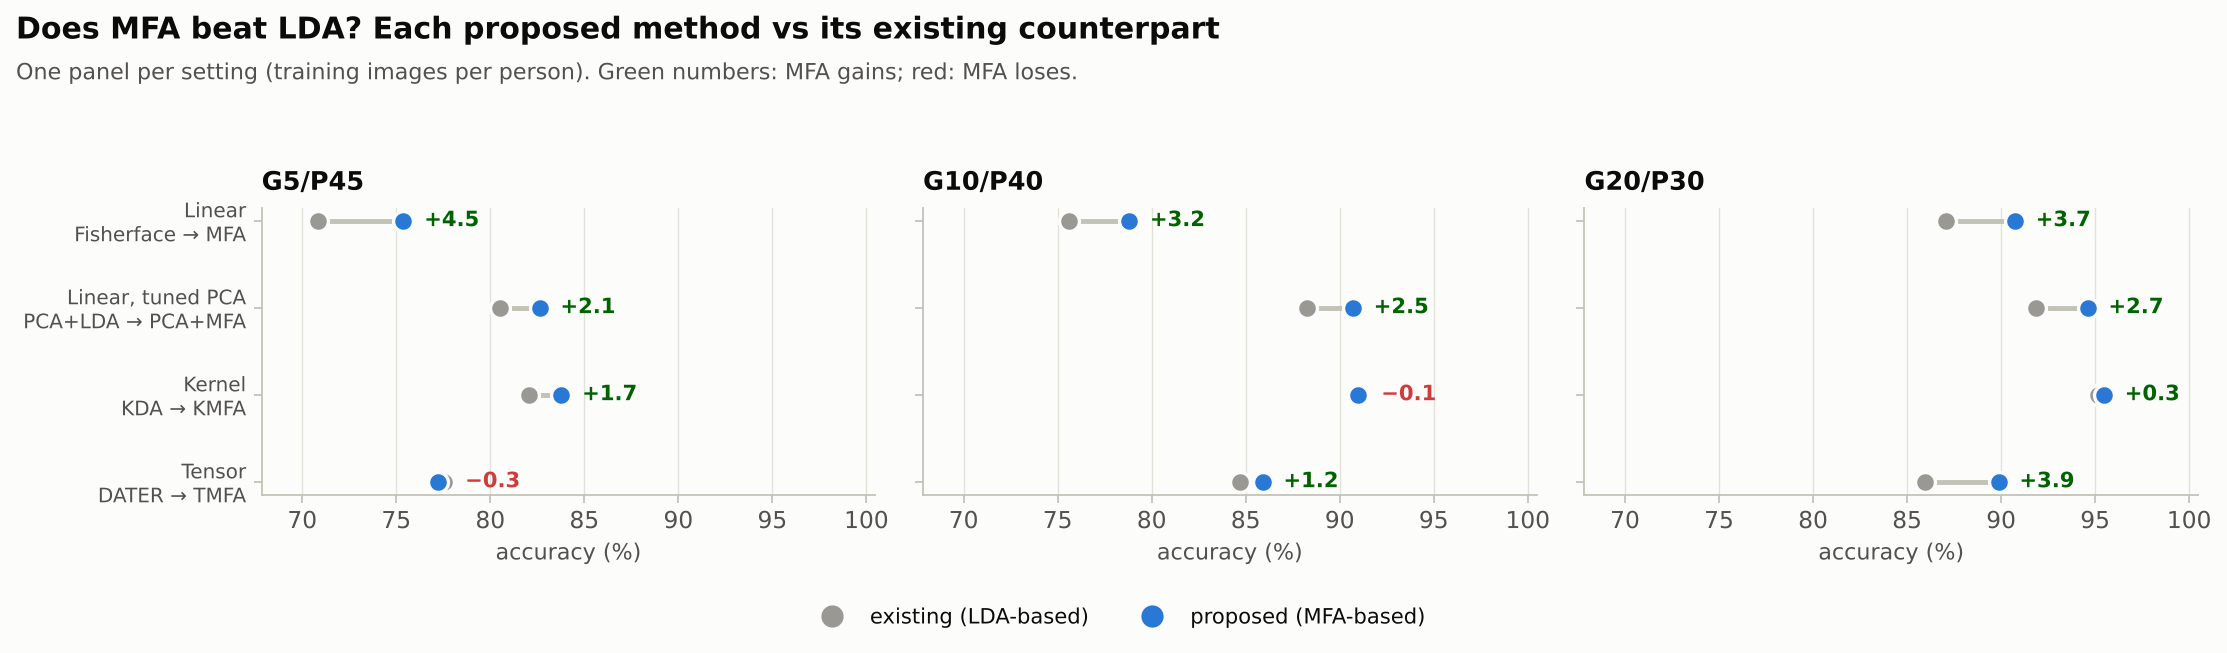

In [15]:
# Plot (folded)
fig, axes = plt.subplots(1, len(results), figsize=(14, 3.6), sharey=True)
axes = np.atleast_1d(axes)
lo, hi = acc.loc[[p for t in PAIRS for p in t[1:]]].values.min(), acc.loc[[p for t in PAIRS for p in t[1:]]].values.max()
for ax, s in zip(axes, acc.columns):
    for i, (kind, a, b) in enumerate(PAIRS):
        y = len(PAIRS) - 1 - i; va, vb = acc.loc[a, s], acc.loc[b, s]
        ax.plot([va, vb], [y, y], color=AXIS, lw=2.2, zorder=1, solid_capstyle="round")
        ax.scatter([va], [y], s=80, color=EXISTING, edgecolors=SURF, linewidths=1.5, zorder=3)
        ax.scatter([vb], [y], s=80, color=PROPOSED, edgecolors=SURF, linewidths=1.5, zorder=3)
        dv = vb - va
        ax.text(max(va, vb) + 0.035 * (hi - lo + 7), y, f"{'+' if dv >= 0 else '−'}{abs(dv):.1f}", va="center", fontsize=9.5,
                color=GOOD_TXT if dv > 0.05 else (BAD if dv < -0.05 else INK2), fontweight="bold")
    ax.set_title(s); ax.set_xlabel("accuracy (%)"); ax.set_xlim(lo - 3, hi + 5); ax.grid(axis="y", visible=False)
    ax.set_yticks(range(len(PAIRS)), [f"{k}\n{a} → {b}" for k, a, b in PAIRS][::-1], fontsize=9)
fig.legend(handles=[Line2D([], [], marker="o", ls="", ms=9, color=EXISTING, label="existing (LDA-based)"),
                    Line2D([], [], marker="o", ls="", ms=9, color=PROPOSED, label="proposed (MFA-based)")],
           loc="lower center", bbox_to_anchor=(0.5, -0.1), ncol=2)
finish(fig, "Does MFA beat LDA? Each proposed method vs its existing counterpart",
       "One panel per setting (training images per person). Green numbers: MFA gains; red: MFA loses.")

## D3. All 13 methods at a glance

Each row is one method. Dots are the three settings, darker for more training images per person, and whiskers show ±1 standard deviation over the splits. The blue band holds the proposed methods.

Saved for slides: figures/08_all_methods_at_a_glance.png  (and .svg)


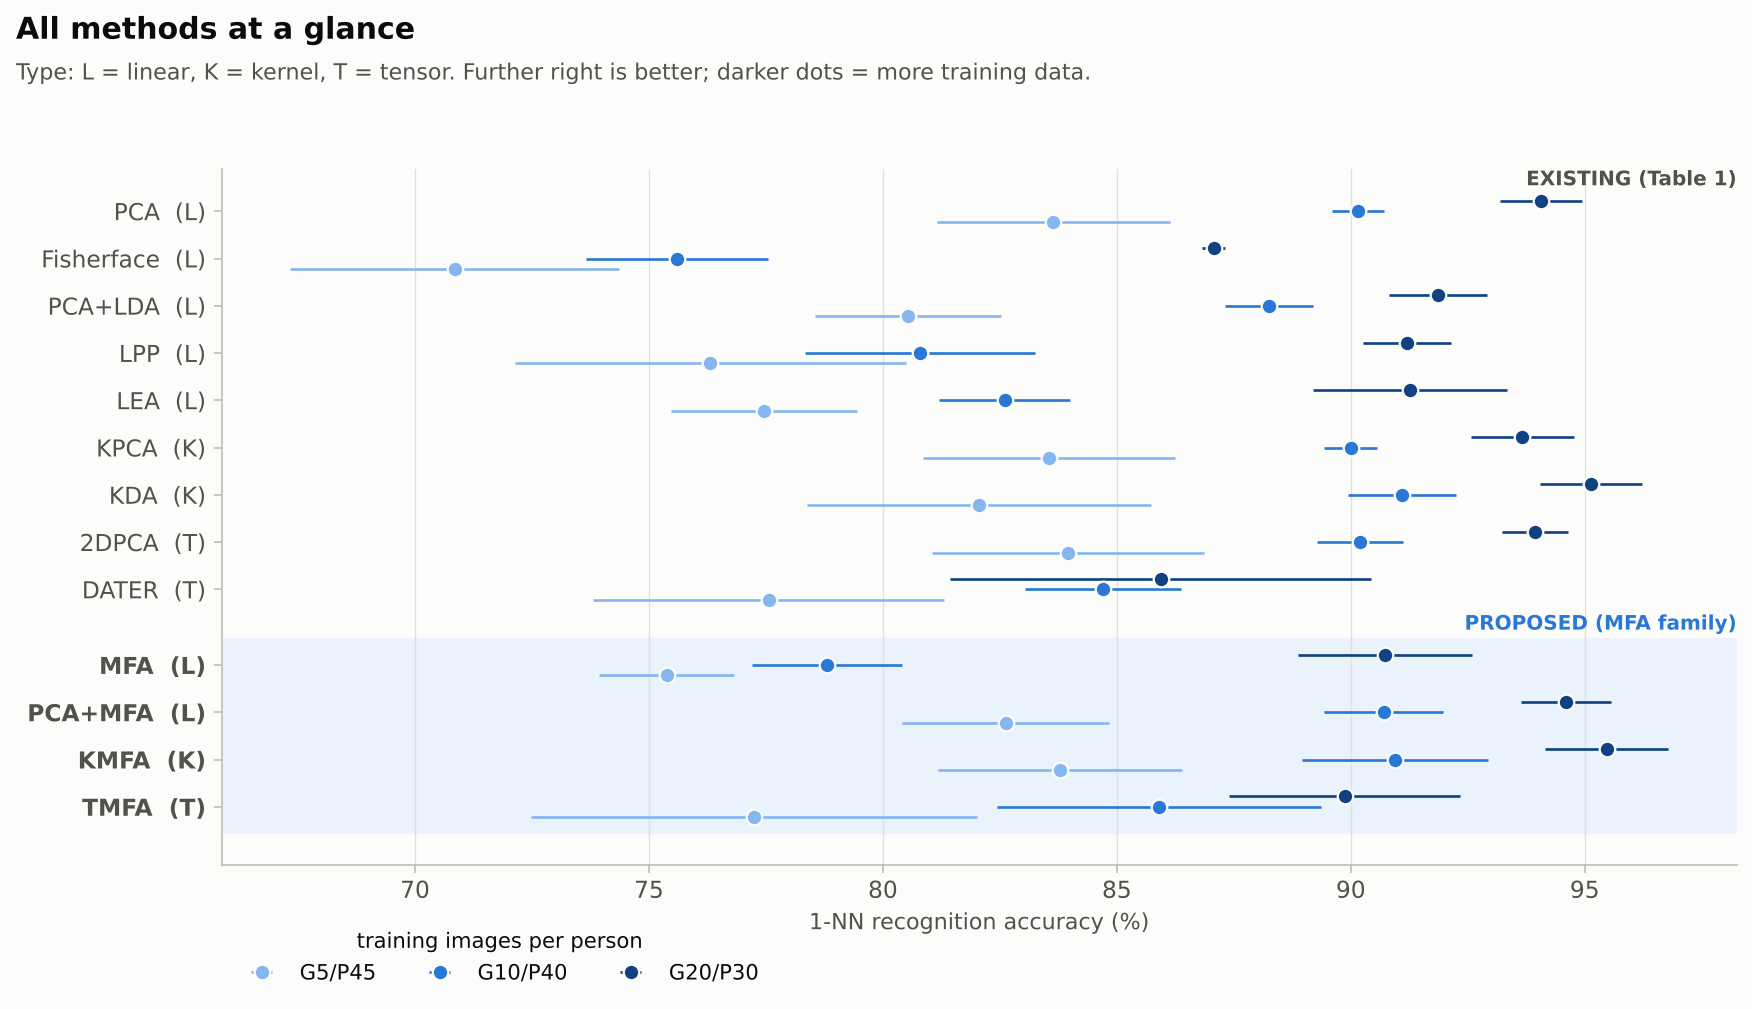

In [16]:
# Plot (folded)
ALL = EXISTING_M + PROPOSED_M
fig, ax = plt.subplots(figsize=(11, 6.4))
ypos = {n: len(ALL) - 1 - i - (0.6 if n in PROPOSED_M else 0) for i, n in enumerate(ALL)}
yb = [ypos[n] for n in PROPOSED_M]
ax.axhspan(min(yb) - 0.55, max(yb) + 0.55, color=PROPOSED_BG, zorder=0)
for j, (s, res) in enumerate(results.items()):
    off = (j - (len(results) - 1) / 2) * 0.22
    for n in ALL:
        ax.errorbar(res[n]["acc"], ypos[n] + off, xerr=res[n]["std"], fmt="o", ms=7, color=SETTING_C[j % 3],
                    ecolor=SETTING_C[j % 3], elinewidth=1.2, capsize=0, markeredgecolor=SURF, markeredgewidth=1, zorder=3,
                    label=s if n == ALL[0] else None)
ax.set_yticks([ypos[n] for n in ALL], [f"{n}  ({TYPE[n]})" for n in ALL])
for lab in ax.get_yticklabels():
    lab.set_fontweight("bold" if lab.get_text().split()[0] in PROPOSED_M else "normal")
ax.grid(axis="y", visible=False); ax.set_xlabel("1-NN recognition accuracy (%)")
ax.text(1.0, max(yb) + 0.75, "PROPOSED (MFA family)", transform=ax.get_yaxis_transform(), ha="right", color=PROPOSED, fontsize=9, fontweight="bold")
ax.text(1.0, ypos[EXISTING_M[0]] + 0.55, "EXISTING (Table 1)", transform=ax.get_yaxis_transform(), ha="right", color=INK2, fontsize=9, fontweight="bold")
ax.legend(title="training images per person", loc="lower left", bbox_to_anchor=(0, -0.2), ncol=len(results))
finish(fig, "All methods at a glance", "Type: L = linear, K = kernel, T = tensor. Further right is better; darker dots = more training data.")

**Reading the results:**
* **D2 is the paper's claim.** Within each type (linear, kernel, tensor), the proposed MFA version is compared with its LDA-based counterpart on the same splits.
* **The unsupervised existing methods** (PCA, KPCA, 2DPCA, LPP and LEA) never see the labels. They are the baselines.
* **More training images per person** (darker dots in D3) raise every method and shrink the gaps between them.

# Part E: Every formula checked

No official code was released, so each implementation is checked against the paper's **own formulas**. For each one, the paper's expression is computed literally, with explicit loops and double sums, and compared with the code. "Error" is the largest difference; values near $10^{-15}$ mean the two agree to floating-point precision.

In [17]:
# Audit (folded): literal formula vs code, on small random problems
ar = np.random.default_rng(1)
N_, C_ = 30, 3
y_ = np.repeat(np.arange(C_), N_ // C_)
X_ = ar.normal(size=(8, N_)) + 2 * ar.normal(size=(8, C_))[:, y_]
W_ = np.abs(ar.normal(size=(N_, N_))); W_ += W_.T
w_ = ar.normal(size=8)
rows = []
rel = lambda a, b: float(np.max(np.abs(np.asarray(a) - np.asarray(b))) / max(1, np.max(np.abs(b))))
gap = lambda A, B: float(np.linalg.norm(np.linalg.qr(A)[0] - np.linalg.qr(B)[0] @ (np.linalg.qr(B)[0].T @ np.linalg.qr(A)[0]), 2))
pairs_ = [(i, j) for i in range(N_) for j in range(N_) if i != j]

lit = sum((w_ @ X_[:, i] - w_ @ X_[:, j]) ** 2 * W_[i, j] for i, j in pairs_)
rows.append(("A", "Eqs. 3–4", "Σ_{i≠j} ‖wᵀx_i − wᵀx_j‖² W_ij  =  2 wᵀXLXᵀw", rel(lit, 2 * w_ @ X_ @ laplacian(W_) @ X_.T @ w_)))
K_ = np.exp(-sqdist(X_, X_) / np.mean(sqdist(X_, X_))); a_ = ar.normal(size=N_)
lit = sum((a_ @ K_[:, i] - a_ @ K_[:, j]) ** 2 * W_[i, j] for i, j in pairs_)
rows.append(("A", "Eq. 5", "Σ ‖αᵀK_i − αᵀK_j‖² W_ij  =  2 αᵀKLKα", rel(lit, 2 * a_ @ K_ @ laplacian(W_) @ K_ @ a_)))
T_ = ar.normal(size=(N_, 6, 5)); U1_, U2_ = ar.normal(size=(6, 3)), ar.normal(size=(5, 2))
lit = sum(np.sum((U1_.T @ (T_[i] - T_[j]) @ U2_) ** 2) * W_[i, j] for i, j in pairs_)
Y_ = T_ @ U2_
code = np.trace(U1_.T @ (2 * np.einsum("iar,ibr->ab", Y_, (laplacian(W_) @ Y_.reshape(N_, -1)).reshape(Y_.shape))) @ U1_)
rows.append(("A", "Eqs. 7–8", "Σ ‖X_i×₁U₁×₂U₂ − X_j×₁U₁×₂U₂‖² W_ij  (tensor objective)", rel(lit, code)))
rows.append(("B", "Eq. 11", "N·C = X(I − eeᵀ/N)Xᵀ  (PCA graph)", rel(N_ * np.cov(X_, bias=True), X_ @ laplacian(W_pca(N_)) @ X_.T)))
rows.append(("B", "Eq. 11", "PCA via the framework (largest λ) spans the SVD principal subspace",
             gap(linear_embedding(X_, W_pca(N_), None, 3, reg=0.0, largest=True), pca(X_, 3)[1])))
mu_ = X_.mean(1, keepdims=True)
SW = sum((X_[:, y_ == c] - X_[:, y_ == c].mean(1, keepdims=True)) @ (X_[:, y_ == c] - X_[:, y_ == c].mean(1, keepdims=True)).T for c in range(C_))
SB = sum(10 * (X_[:, y_ == c].mean(1, keepdims=True) - mu_) @ (X_[:, y_ == c].mean(1, keepdims=True) - mu_).T for c in range(C_))
rows.append(("B", "Eq. 12", "S_W = X(I − Σ_c e^c e^cᵀ/n_c)Xᵀ  (LDA graph)", rel(SW, X_ @ laplacian(W_lda(y_)) @ X_.T)))
ev, EV = np.linalg.eig(np.linalg.solve(SW, SB))
rows.append(("B", "Eq. 12", "graph-embedding LDA spans the classical Fisher subspace",
             gap(linear_embedding(X_, W_lda(y_), B_centering(N_), C_ - 1, reg=0.0), np.real(EV[:, np.argsort(-np.real(ev))[:C_ - 1]]))))
Xc, _ = make_s_curve(120, random_state=1); tau = isomap_tau(Xc.T, 8)
rows.append(("B", "App. A", "rows of τ(D_G) sum to 0, so ISOMAP is graph embedding", float(np.abs(tau.sum(1)).max() / np.abs(tau).max())))
M_ = lle_weights(Xc.T, 8); I_ = np.eye(len(M_))
rows.append(("B", "App. B", "(I−M)ᵀ(I−M) = L(M + Mᵀ − MᵀM)  (LLE graph)", rel((I_ - M_).T @ (I_ - M_), laplacian(W_lle(Xc.T, 8)))))
rows.append(("B", "Table 1 ✗", "as printed, W = M + Mᵀ + MᵀM: a sign typo in the paper", rel((I_ - M_).T @ (I_ - M_), laplacian(M_ + M_.T + M_.T @ M_))))
d_ = cdist(X_.T, X_.T); Nk = {i: set(np.argsort(d_[i])[1:5]) for i in range(N_)}
W_le_lit = np.array([[np.exp(-d_[i, j] ** 2 / 3.0) if (i in Nk[j] or j in Nk[i]) else 0.0 for j in range(N_)] for i in range(N_)])
rows.append(("B", "Table 1", "LE/LPP graph: e^{−‖x_i−x_j‖²/t} iff i ∈ N_k(j) or j ∈ N_k(i)", rel(W_heat_knn(X_, 4, t=3.0), W_le_lit)))
Wm, Wpm = mfa_graphs(y_, 3, 12, d_)
nn_ = {i: set(sorted([j for j in range(N_) if y_[j] == y_[i] and j != i], key=lambda j: d_[i, j])[:3]) for i in range(N_)}
W_lit = np.array([[float(i in nn_[j] or j in nn_[i]) for j in range(N_)] for i in range(N_)])
rows.append(("C", "Eq. 13", "intrinsic graph: W_ij = 1 iff i ∈ N⁺_k1(j) or j ∈ N⁺_k1(i)", float(np.abs(Wm - W_lit).max())))
P_ = {c: set(sorted([(i, j) for i in range(N_) if y_[i] == c for j in range(N_) if y_[j] != c], key=lambda p: d_[p])[:12]) for c in range(C_)}
Wp_lit = np.array([[float(any(p in P_[y_[a]] for a in (i, j) for p in ((i, j), (j, i)))) for j in range(N_)] for i in range(N_)])
rows.append(("C", "Eq. 14", "penalty graph: the k₂ closest cross-class pairs of each class", float(np.abs(Wpm - Wp_lit).max())))
A15, B15 = X_ @ laplacian(Wm) @ X_.T, X_ @ laplacian(Wpm) @ X_.T
w15 = mfa(X_, y_, 3, 12, 1)[:, 0]; R_ = ar.normal(size=(8, 20000))
best = (w15 @ A15 @ w15) / (w15 @ B15 @ w15) - (np.einsum("ij,ik,kj->j", R_, A15, R_) / np.einsum("ij,ik,kj->j", R_, B15, R_)).min()
rows.append(("C", "Eq. 15", "solver beats 20,000 random directions on the MFA ratio", max(0.0, best)))
Kq = np.exp(-sqdist(X_, X_) / 50.0); Aq = kmfa(Kq, y_, 3, 12)
rows.append(("C", "Eq. 17", "λ = (αᵀKα)^(−1/2) makes each KMFA direction unit length", float(np.abs(np.einsum("ip,ij,jp->p", Aq, Kq, Aq) - 1).max())))

audit = pd.DataFrame(rows, columns=["part", "paper", "formula checked (literal computation vs code)", "error"])
audit["result"] = ["✗ (expected)" if p.startswith("Table 1 ✗") else ("✓" if e < 1e-8 else "✗") for p, e in zip(audit["paper"], audit["error"])]
audit["error"] = audit["error"].map(lambda v: f"{v:.0e}")
res_col = lambda v: (f"color: {GOOD_TXT}; font-weight: 700" if v == "✓" else f"color: {MUTED}; font-style: italic")
display(audit.style.hide(axis="index").map(res_col, subset=["result"]).set_table_styles(TH)
        .set_properties(**{"text-align": "left"})
        .set_caption("Each formula computed literally (loops and double sums) vs the notebook's code; error ≈ 1e-15 means identical"))

part,paper,formula checked (literal computation vs code),error,result
A,Eqs. 3–4,Σ_{i≠j} ‖wᵀx_i − wᵀx_j‖² W_ij = 2 wᵀXLXᵀw,9e-16,✓
A,Eq. 5,Σ ‖αᵀK_i − αᵀK_j‖² W_ij = 2 αᵀKLKα,2e-15,✓
A,Eqs. 7–8,Σ ‖X_i×₁U₁×₂U₂ − X_j×₁U₁×₂U₂‖² W_ij (tensor objective),7e-16,✓
B,Eq. 11,N·C = X(I − eeᵀ/N)Xᵀ (PCA graph),3e-16,✓
B,Eq. 11,PCA via the framework (largest λ) spans the SVD principal subspace,1e-15,✓
B,Eq. 12,S_W = X(I − Σ_c e^c e^cᵀ/n_c)Xᵀ (LDA graph),2e-16,✓
B,Eq. 12,graph-embedding LDA spans the classical Fisher subspace,2e-15,✓
B,App. A,"rows of τ(D_G) sum to 0, so ISOMAP is graph embedding",2e-14,✓
B,App. B,(I−M)ᵀ(I−M) = L(M + Mᵀ − MᵀM) (LLE graph),4e-16,✓
B,Table 1 ✗,"as printed, W = M + Mᵀ + MᵀM: a sign typo in the paper",1e+00,✗ (expected)


# Takeaways

1. **Part A, one framework.** Every method here, existing or proposed, is one call to `solve_ge` on a graph $(W, B)$ through the direct, linear, kernel or tensor form.
2. **Part B, existing algorithms.** PCA, LDA, ISOMAP, LLE and Laplacian Eigenmap/LPP, with their kernel and tensor versions, are just Table 1's graphs plugged into Part A.
3. **Part C, the proposal.** MFA replaces LDA's class-mean graphs with $k_1$-neighbour and $k_2$-border-pair graphs. This removes the Gaussian assumption (the toy problem) and the $N_c-1$ limit. Kernel and tensor MFA follow automatically from the framework.
4. **Part D, the evidence.** The combined table compares all 13 methods on the same splits. The difference table isolates the paper's claim: MFA against LDA within each type.
5. **Part E, correctness.** Each formula matches a literal computation to floating-point precision, and the check exposes a sign typo in Table 1's LLE entry.

# F. Slide versions of Figures 2, 4 and 7

The figures above are wide strips that become too small on a slide. This section redraws three of them for slides. There are no titles, because the slide title does that job. Fonts are larger, and each piece is saved on its own in **`figures/slides/`** as PDF (vector, for LaTeX) and PNG (300 dpi). Rerunning overwrites them.

| File | Content |
|---|---|
| `fig2_direct_embeddings_2x2` | Figure 2 as a 2×2 grid: input sheet, ISOMAP, LLE, Laplacian Eigenmap |
| `fig4a_data_and_directions` | Figure 4, left panel: the toy data with the LDA and MFA directions |
| `fig4b_lda_projection`, `fig4c_mfa_projection` | Figure 4, the two projections separately |
| `fig4bc_projections_stacked` | the two projections stacked, sharing the x-axis label style |
| `fig7_<setting>` | Figure 7, one file per setting (same x-axis range, so they compare) |

In [18]:
# Slide-figure helpers (folded)
SLIDE_DIR = os.path.join(FIG_DIR, "slides")
os.makedirs(SLIDE_DIR, exist_ok=True)
SLIDE_RC = {"font.size": 13, "axes.titlesize": 15, "axes.labelsize": 13, "xtick.labelsize": 12,
            "ytick.labelsize": 12, "legend.fontsize": 12}


def save_slide(fig, name):
    base = os.path.join(SLIDE_DIR, name)
    fig.savefig(base + ".pdf", bbox_inches="tight")
    fig.savefig(base + ".png", dpi=300, bbox_inches="tight")
    print("Saved for slides:", os.path.abspath(base) + ".pdf  (and .png)")
    getattr(plt, "_original_show", plt.show)()   # skip any auto-save patch, so these are not saved twice

Saved for slides: /home/claude/nb/figures/slides/fig2_direct_embeddings_2x2.pdf  (and .png)


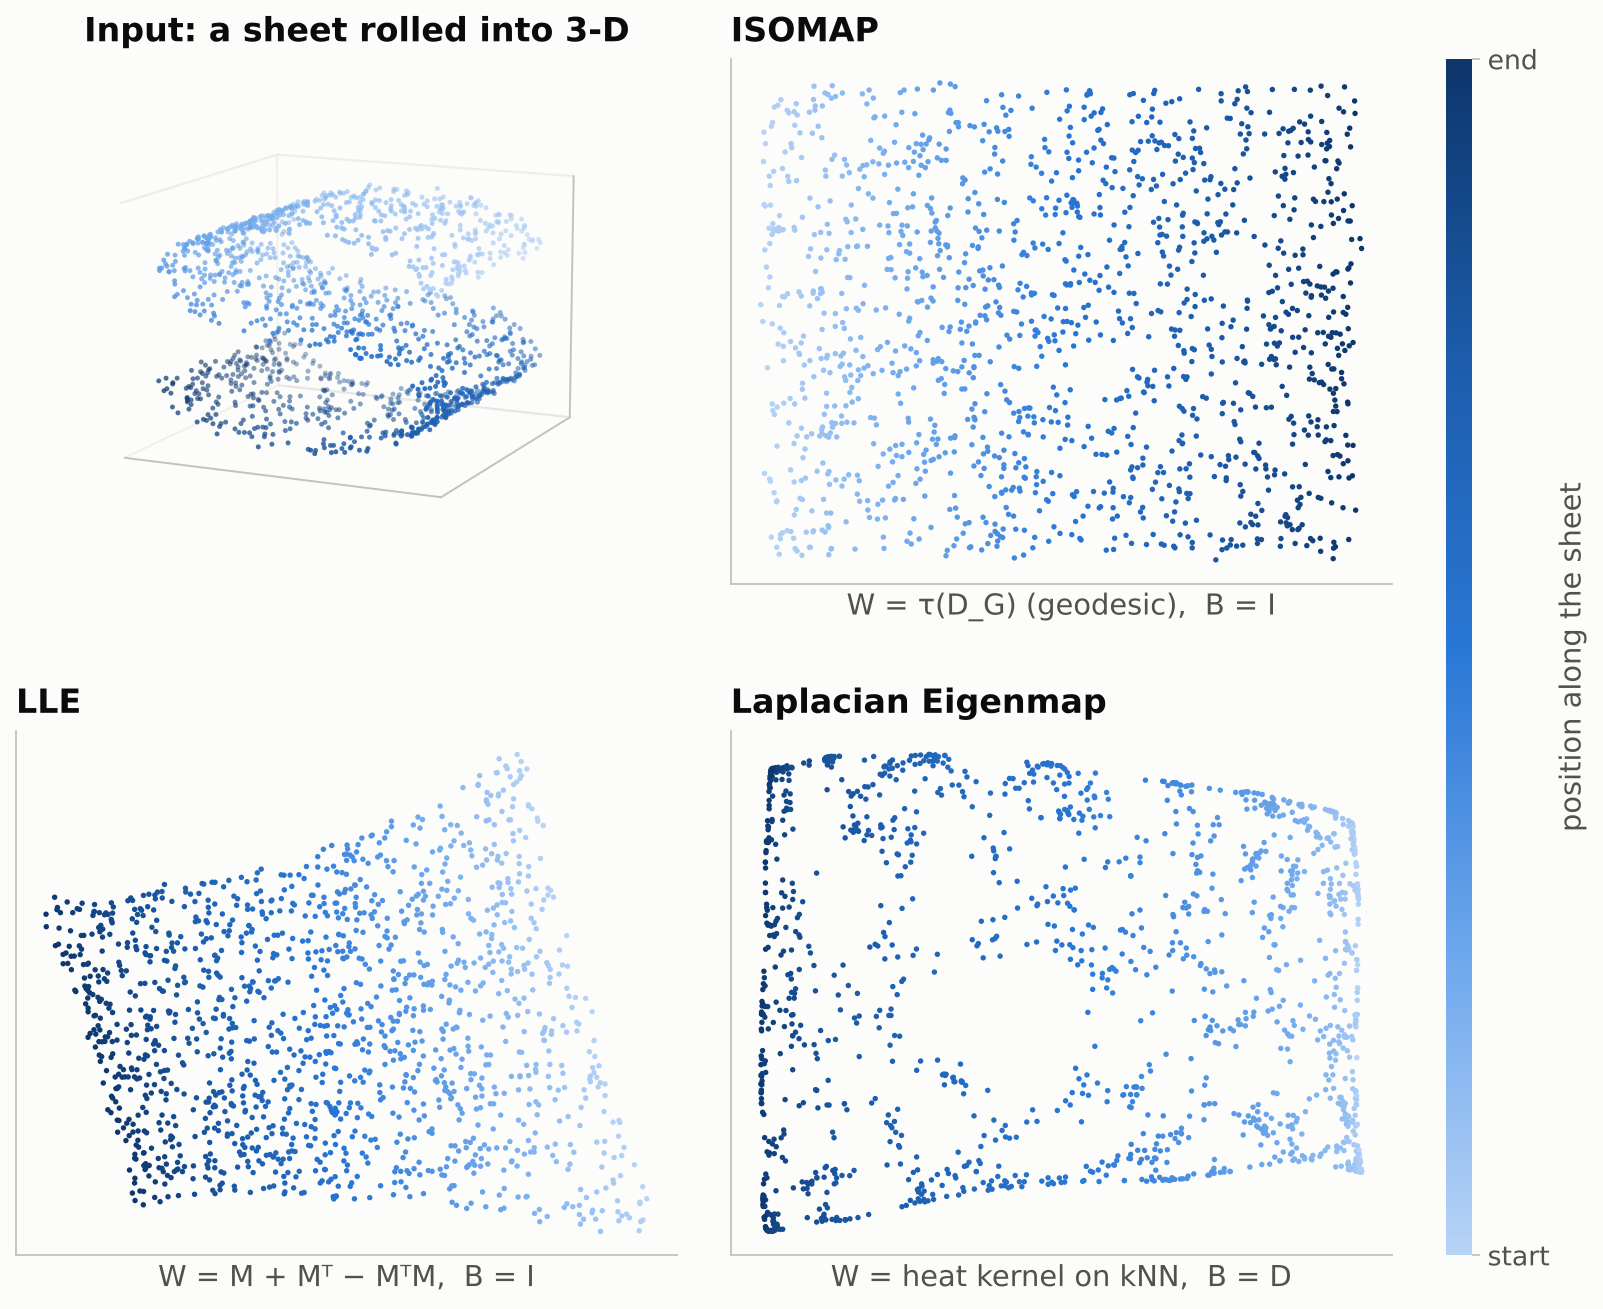

In [19]:
# Figure 2 as a 2x2 grid (folded)
with plt.rc_context(SLIDE_RC):
    fig = plt.figure(figsize=(10, 8.4))
    gs = fig.add_gridspec(2, 3, width_ratios=[1, 1, 0.04], wspace=0.12, hspace=0.28, left=0.02, right=0.93, top=0.95, bottom=0.06)
    ax = fig.add_subplot(gs[0, 0], projection="3d")
    ax.scatter(*Xs, c=t_s, cmap=SEQ, s=5, linewidths=0); ax.view_init(12, -65)
    ax.set_xticks([]); ax.set_yticks([]); ax.set_zticks([])
    ax.set_title("Input: a sheet rolled into 3-D", loc="left")
    for pane in (ax.xaxis.pane, ax.yaxis.pane, ax.zaxis.pane):
        pane.set_facecolor(SURF); pane.set_edgecolor(GRID)
    wb = ["W = τ(D_G) (geodesic),  B = I", "W = M + Mᵀ − MᵀM,  B = I", "W = heat kernel on kNN,  B = D"]
    for (name, Y), lab, pos in zip(direct.items(), wb, [gs[0, 1], gs[1, 0], gs[1, 1]]):
        ax = fig.add_subplot(pos)
        sc = ax.scatter(Y[:, 0], Y[:, 1], c=t_s, cmap=SEQ, s=6, linewidths=0)
        ax.set_title(name.split(":")[0], loc="left"); ax.set_xlabel(lab, color=INK2)
        ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
    cb = fig.colorbar(sc, cax=fig.add_subplot(gs[:, 2]), ticks=[t_s.min(), t_s.max()])
    cb.ax.set_yticklabels(["start", "end"]); cb.set_label("position along the sheet", color=INK2); cb.outline.set_visible(False)
    save_slide(fig, "fig2_direct_embeddings_2x2")

Saved for slides: /home/claude/nb/figures/slides/fig4a_data_and_directions.pdf  (and .png)


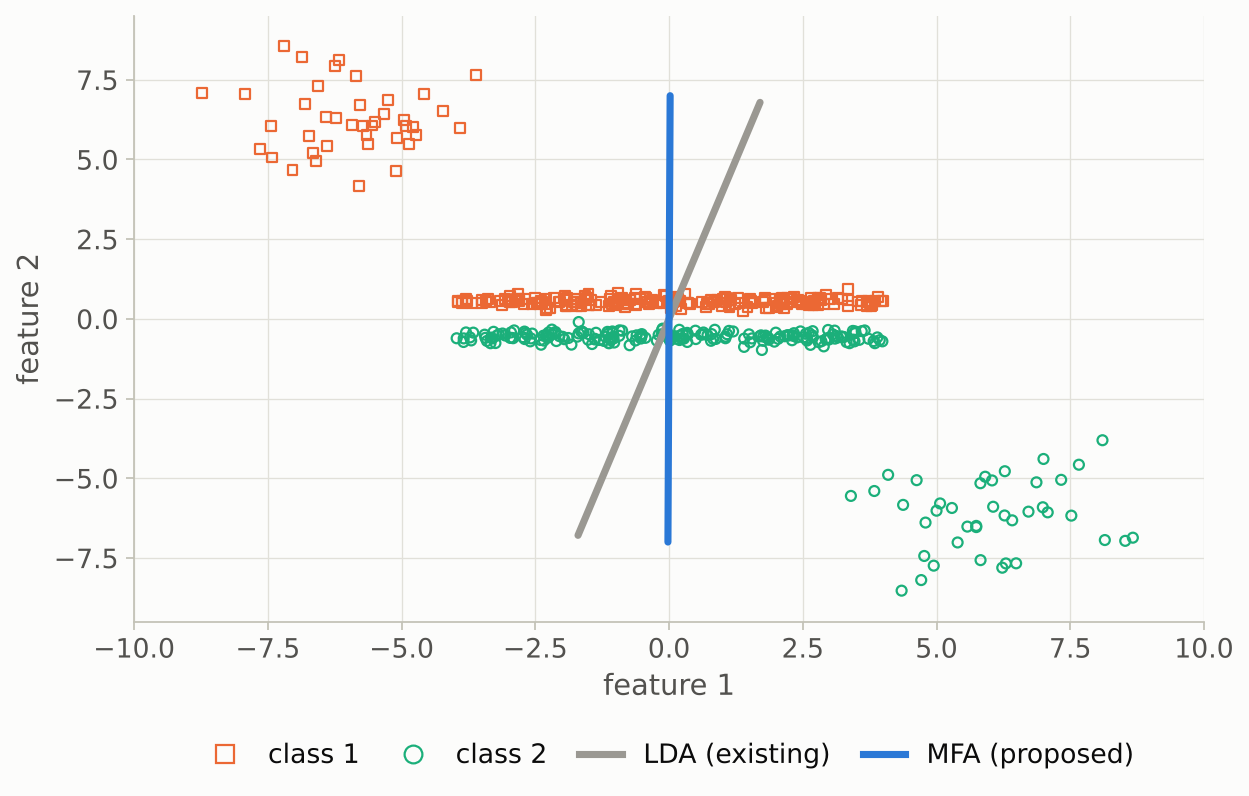

Saved for slides: /home/claude/nb/figures/slides/fig4b_lda_projection.pdf  (and .png)


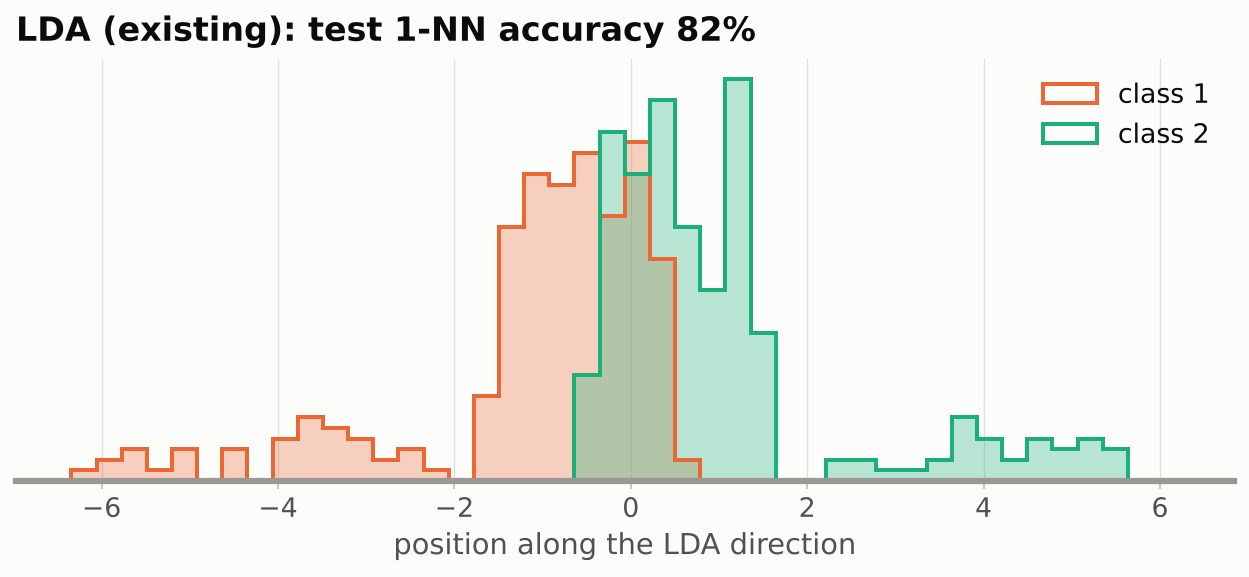

Saved for slides: /home/claude/nb/figures/slides/fig4c_mfa_projection.pdf  (and .png)


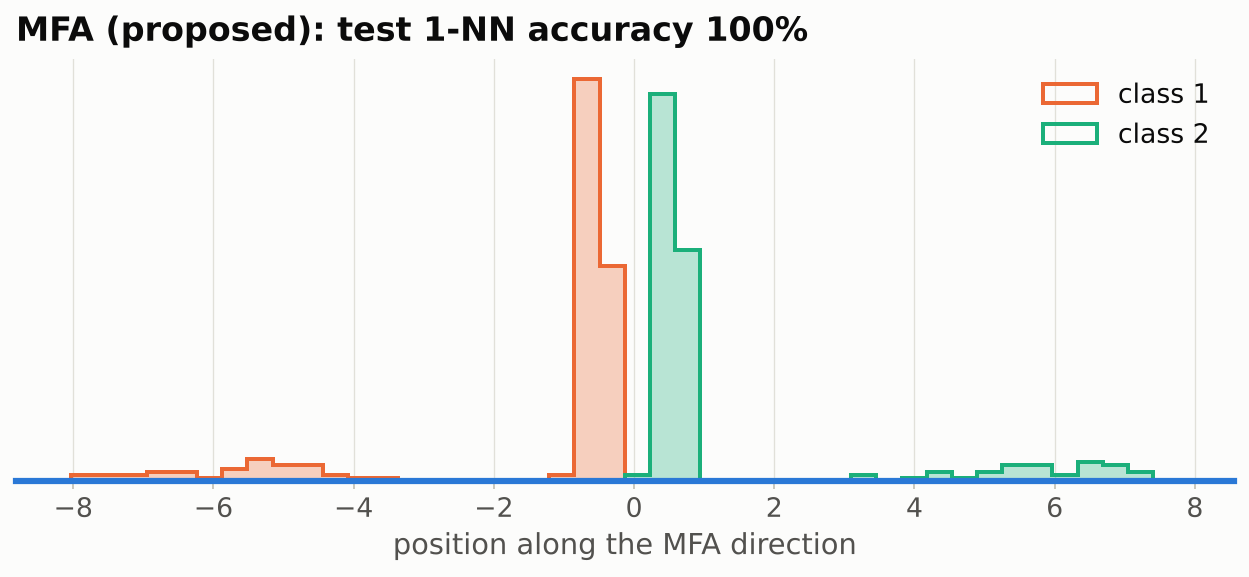

Saved for slides: /home/claude/nb/figures/slides/fig4bc_projections_stacked.pdf  (and .png)


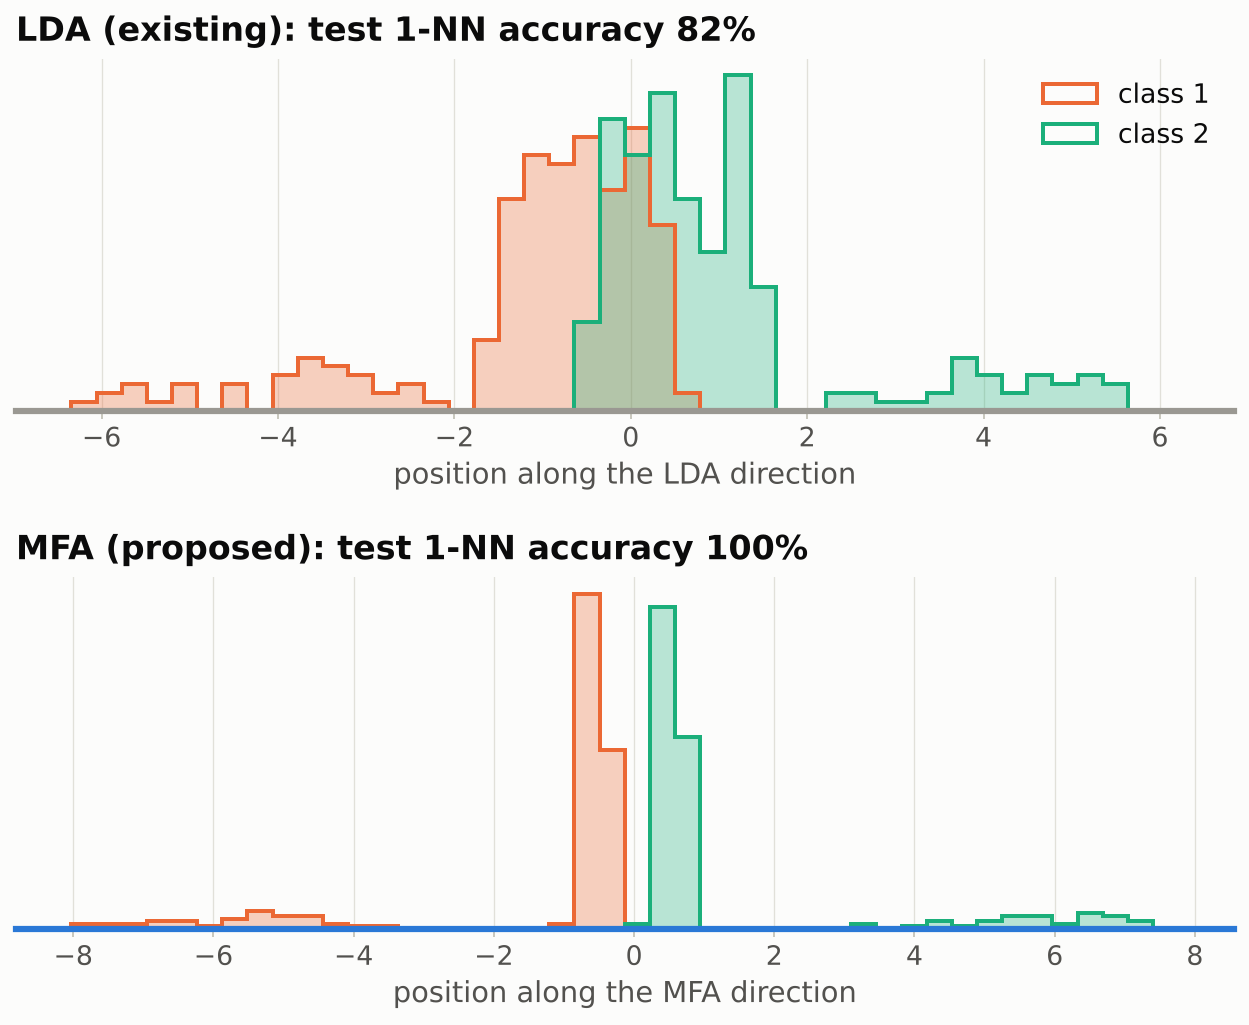

In [20]:
# Figure 4 as separate pieces (folded)
def draw_toy_data(ax):
    for k in (0, 1):
        ax.scatter(*Xt[:, yt == k], marker=TOY_M[k], s=20, facecolors="none", edgecolors=TOY_C[k], linewidths=1)
    for name, (w, col) in dirs.items():
        u = w * np.sign(w[1]); ax.plot([-7 * u[0], 7 * u[0]], [-7 * u[1], 7 * u[1]], color=col, lw=3.2, solid_capstyle="round")
    ax.set_xlim(-10, 10); ax.set_ylim(-9.5, 9.5); ax.set_xlabel("feature 1"); ax.set_ylabel("feature 2")
    ax.legend(handles=[Line2D([], [], marker=TOY_M[k], ls="", ms=8, markerfacecolor="none", markeredgecolor=TOY_C[k], label=f"class {k + 1}") for k in (0, 1)]
              + [Line2D([], [], color=c, lw=3.2, label=n) for n, (w, c) in dirs.items()],
              loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=4, frameon=False, handlelength=1.6, columnspacing=1.2)


def draw_projection(ax, name, w, col, legend=True):
    p, q = w @ Xt, w @ Xv
    bins = np.linspace(np.percentile(p, 0.5), np.percentile(p, 99.5), 45)
    for k in (0, 1):
        ax.hist(q[yv == k], bins, color=TOY_C[k], alpha=0.30, histtype="stepfilled")
        ax.hist(q[yv == k], bins, color=TOY_C[k], lw=1.8, histtype="step", label=f"class {k + 1}")
    acc_ = nn_acc(p[None], q[None], yt, yv)
    ax.set_title(f"{name}: test 1-NN accuracy {acc_:.0%}", loc="left")
    ax.set_xlabel(f"position along the {name.split()[0]} direction")
    ax.set_yticks([]); ax.grid(axis="y", visible=False); ax.spines["left"].set_visible(False)
    ax.spines["bottom"].set_color(col); ax.spines["bottom"].set_linewidth(2.8)
    if legend: ax.legend(loc="upper right", frameon=False)


with plt.rc_context(SLIDE_RC):
    fig, ax = plt.subplots(figsize=(8, 5.2)); draw_toy_data(ax); fig.tight_layout(); save_slide(fig, "fig4a_data_and_directions")
    for tag, (name, (w, col)) in zip("bc", dirs.items()):
        fig, ax = plt.subplots(figsize=(8, 3.8)); draw_projection(ax, name, w, col); fig.tight_layout()
        save_slide(fig, f"fig4{tag}_{name.split()[0].lower()}_projection")
    fig, axes = plt.subplots(2, 1, figsize=(8, 6.6))
    for i, (ax, (name, (w, col))) in enumerate(zip(axes, dirs.items())):
        draw_projection(ax, name, w, col, legend=(i == 0))
    fig.tight_layout(h_pad=1.5); save_slide(fig, "fig4bc_projections_stacked")

Saved for slides: /home/claude/nb/figures/slides/fig7_G5_P45.pdf  (and .png)


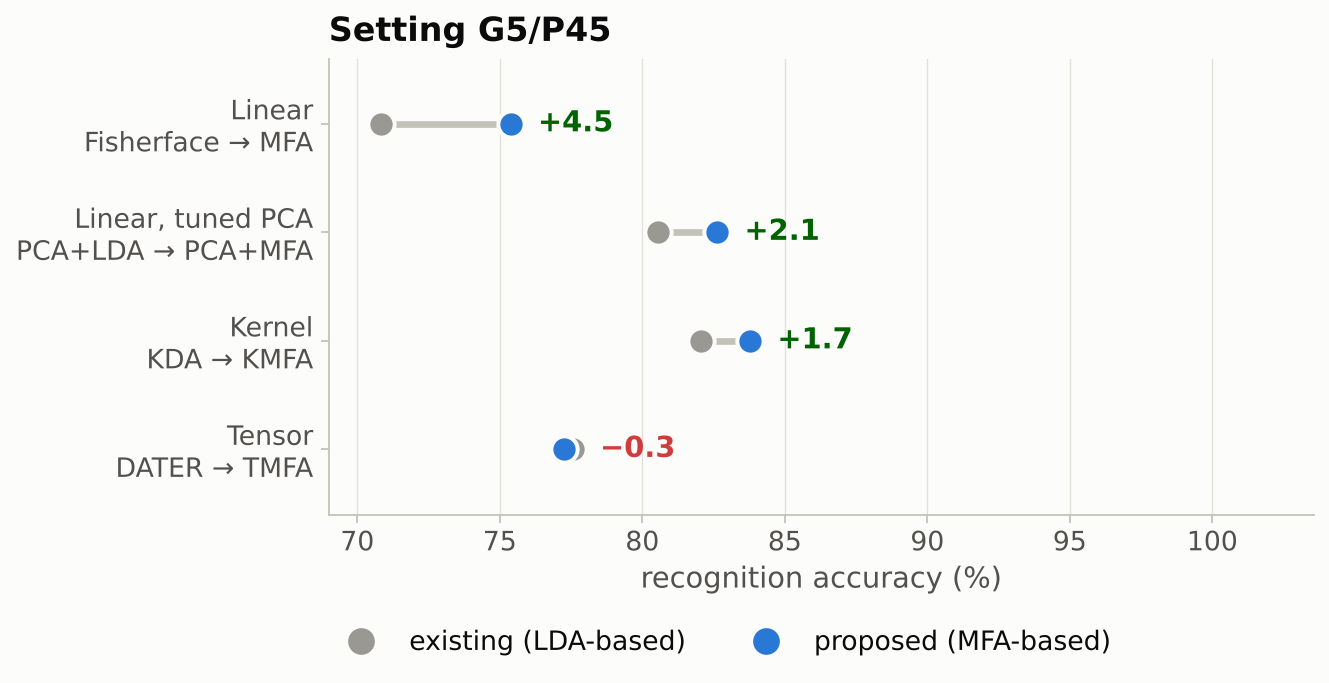

Saved for slides: /home/claude/nb/figures/slides/fig7_G10_P40.pdf  (and .png)


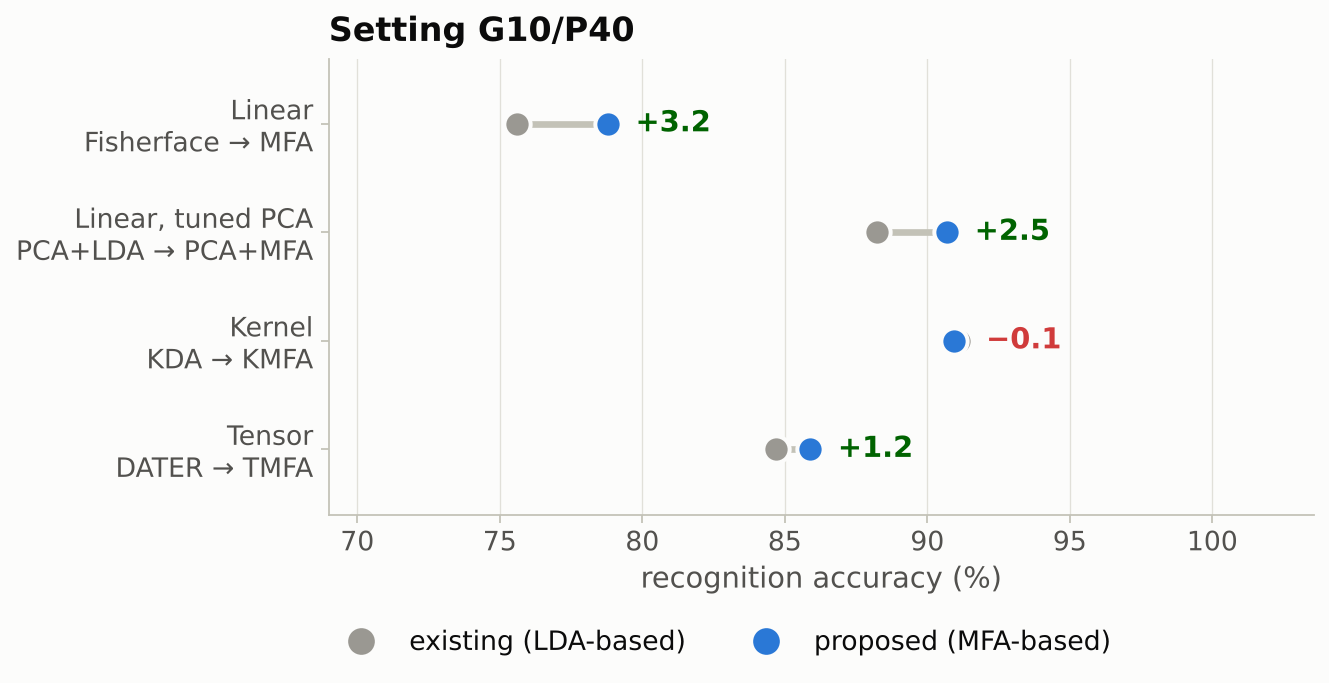

Saved for slides: /home/claude/nb/figures/slides/fig7_G20_P30.pdf  (and .png)


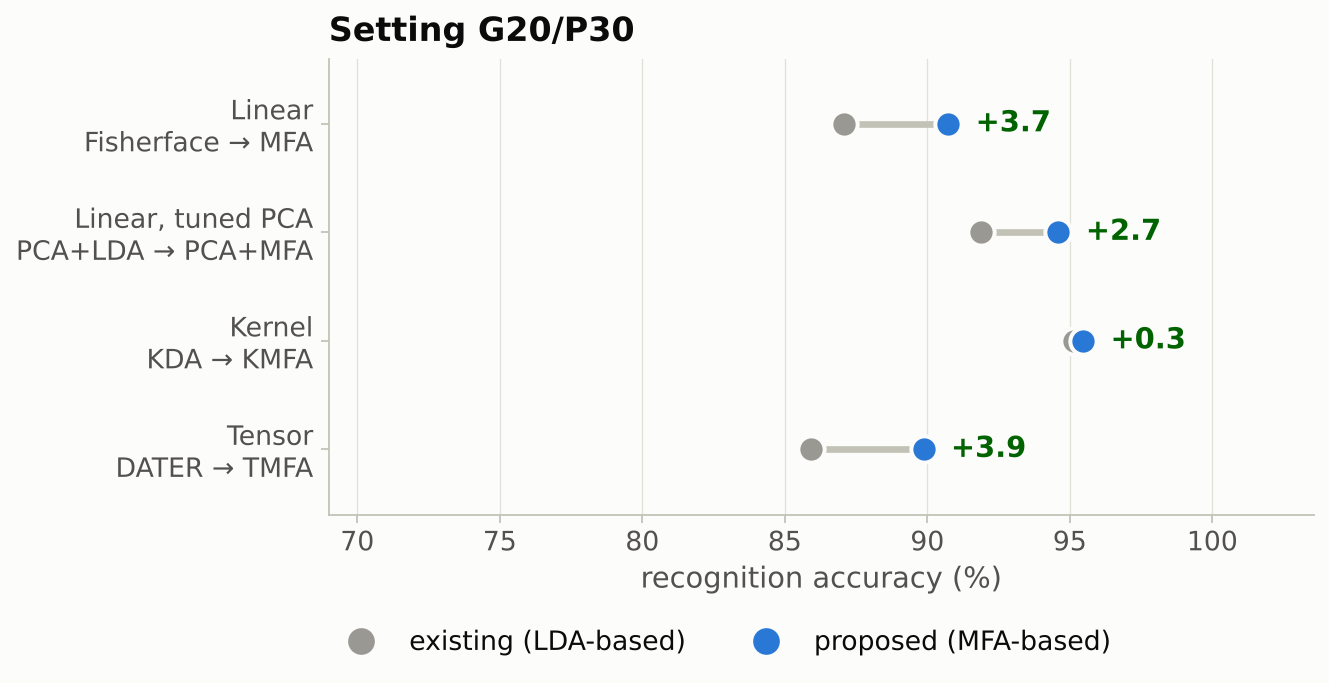

In [21]:
# Figure 7, one file per setting (folded)
pair_vals = acc.loc[[p for t in PAIRS for p in t[1:]]].values
lo7, hi7 = np.floor(pair_vals.min() / 5) * 5 - 1, max(100, np.ceil(pair_vals.max() / 5) * 5) + 1
with plt.rc_context(SLIDE_RC):
    for s in acc.columns:
        fig, ax = plt.subplots(figsize=(8.5, 4.6))
        for i, (kind, a, b) in enumerate(PAIRS):
            y = len(PAIRS) - 1 - i; va, vb = acc.loc[a, s], acc.loc[b, s]
            ax.plot([va, vb], [y, y], color=AXIS, lw=3, zorder=1, solid_capstyle="round")
            ax.scatter([va], [y], s=140, color=EXISTING, edgecolors=SURF, linewidths=1.8, zorder=3)
            ax.scatter([vb], [y], s=140, color=PROPOSED, edgecolors=SURF, linewidths=1.8, zorder=3)
            dv = vb - va
            ax.text(max(va, vb) + 0.03 * (hi7 - lo7), y, f"{'+' if dv >= 0 else '−'}{abs(dv):.1f}", va="center", fontsize=13,
                    color=GOOD_TXT if dv > 0.05 else (BAD if dv < -0.05 else INK2), fontweight="bold")
        ax.set_yticks(range(len(PAIRS)), [f"{k}\n{a} → {b}" for k, a, b in PAIRS][::-1])
        ax.set_xlim(lo7, hi7 + 0.08 * (hi7 - lo7)); ax.set_ylim(-0.6, len(PAIRS) - 0.4)
        ax.set_xlabel("recognition accuracy (%)"); ax.grid(axis="y", visible=False)
        ax.set_title(f"Setting {s}", loc="left")
        ax.legend(handles=[Line2D([], [], marker="o", ls="", ms=11, color=EXISTING, label="existing (LDA-based)"),
                           Line2D([], [], marker="o", ls="", ms=11, color=PROPOSED, label="proposed (MFA-based)")],
                  loc="upper center", bbox_to_anchor=(0.4, -0.2), ncol=2, frameon=False)
        fig.tight_layout()
        save_slide(fig, "fig7_" + re.sub(r"[^A-Za-z0-9]+", "_", str(s)).strip("_"))

## F2. Results tables as LaTeX (for the slides)

This cell writes your own accuracy numbers into two ready-to-use LaTeX tables in `figures/slides/`:
- `results_pairs.tex` is the paper's main claim. Each existing method sits next to its MFA version. The better one is in bold, and the gain is shown in green or red.
- `results_all.tex` lists all 13 methods, with the best value in each column in bold.

Use `\input{slides/results_pairs.tex}` inside a frame. It needs `\usepackage{booktabs}`.

In [22]:
# Write LaTeX tables (folded)
def tex(s): return str(s).replace("&", r"\&").replace("%", r"\%").replace("_", r"\_")
cols = list(acc.columns)
head = " & ".join(tex(c) for c in cols)

L = [r"\begin{tabular}{ll" + "c" * len(cols) + "}", r"\toprule",
     r"\textbf{Type} & \textbf{Method} & " + " & ".join(r"\textbf{" + tex(c) + "}" for c in cols) + r" \\", r"\midrule"]
for i, (kind, a, b) in enumerate(PAIRS):
    ea, eb = [], []
    for c in cols:
        va, vb = acc.loc[a, c], acc.loc[b, c]; d = vb - va
        col = "green!50!black" if d > 0.05 else ("red" if d < -0.05 else "gray")
        ea.append((r"\textbf{%.1f}" if va > vb else "%.1f") % va)
        eb.append((r"\textbf{%.1f}" if vb >= va else "%.1f") % vb + r" {\scriptsize\textcolor{%s}{(%s%.1f)}}" % (col, "+" if d >= 0 else "$-$", abs(d)))
    L.append(f"{tex(kind)} & {tex(a)} & " + " & ".join(ea) + r" \\")
    L.append(r" & \textcolor{blue}{" + tex(b) + "} & " + " & ".join(eb) + r" \\")
    if i < len(PAIRS) - 1: L.append(r"\midrule")
L += [r"\bottomrule", r"\end{tabular}"]
open(os.path.join(SLIDE_DIR, "results_pairs.tex"), "w").write("\n".join(L) + "\n")

best_ = {c: acc[c].max() for c in cols}
L = [r"\begin{tabular}{ll" + "c" * len(cols) + "}", r"\toprule",
     r" & \textbf{Method} & " + " & ".join(r"\textbf{" + tex(c) + "}" for c in cols) + r" \\", r"\midrule"]
for g, ms in (("Existing", EXISTING_M), ("Proposed", PROPOSED_M)):
    for j, m in enumerate(ms):
        name = tex(m) if g == "Existing" else r"\textcolor{blue}{" + tex(m) + "}"
        vals = [(r"\textbf{%.1f}" if abs(acc.loc[m, c] - best_[c]) < 1e-9 else "%.1f") % acc.loc[m, c] for c in cols]
        L.append((g if j == 0 else "") + f" & {name} & " + " & ".join(vals) + r" \\")
    if g == "Existing": L.append(r"\midrule")
L += [r"\bottomrule", r"\end{tabular}"]
open(os.path.join(SLIDE_DIR, "results_all.tex"), "w").write("\n".join(L) + "\n")

print("Saved:", os.path.abspath(os.path.join(SLIDE_DIR, "results_pairs.tex")))
print("Saved:", os.path.abspath(os.path.join(SLIDE_DIR, "results_all.tex")))
print("\n--- results_pairs.tex ---\n" + open(os.path.join(SLIDE_DIR, "results_pairs.tex")).read())

Saved: /home/claude/nb/figures/slides/results_pairs.tex
Saved: /home/claude/nb/figures/slides/results_all.tex

--- results_pairs.tex ---
\begin{tabular}{llccc}
\toprule
\textbf{Type} & \textbf{Method} & \textbf{G5/P45} & \textbf{G10/P40} & \textbf{G20/P30} \\
\midrule
Linear & Fisherface & 70.8 & 75.6 & 87.1 \\
 & \textcolor{blue}{MFA} & \textbf{75.4} {\scriptsize\textcolor{green!50!black}{(+4.5)}} & \textbf{78.8} {\scriptsize\textcolor{green!50!black}{(+3.2)}} & \textbf{90.7} {\scriptsize\textcolor{green!50!black}{(+3.7)}} \\
\midrule
Linear, tuned PCA & PCA+LDA & 80.5 & 88.2 & 91.9 \\
 & \textcolor{blue}{PCA+MFA} & \textbf{82.6} {\scriptsize\textcolor{green!50!black}{(+2.1)}} & \textbf{90.7} {\scriptsize\textcolor{green!50!black}{(+2.5)}} & \textbf{94.6} {\scriptsize\textcolor{green!50!black}{(+2.7)}} \\
\midrule
Kernel & KDA & 82.0 & \textbf{91.1} & 95.1 \\
 & \textcolor{blue}{KMFA} & \textbf{83.8} {\scriptsize\textcolor{green!50!black}{(+1.7)}} & 91.0 {\scriptsize\textcolor{red}{($